# 🐾 Detector și numărător YOLOv8: **Animal** vs **Non_Animal**

Binary object detector (2 classes) for JupyterLab · Python 3.12 · Windows

| ID | Class | Examples |
|---|---|---|
| **0** | `Non_Animal` | remote, cup, cell phone, car, chair, laptop, bottle… |
| **1** | `Animal` | dog, cat, horse, bird, sheep, cow, elephant, bear, zebra, giraffe |

**How to use this notebook:** run the cells **from top to bottom**, one at a time (`Shift + Enter`).
A cell is finished when the `[*]` on its left turns into a number like `[5]`.

**Contents**
- **Step 0** – Install the libraries (once)
- **Step 1** – Download a clean dataset + create `data.yaml`
- **Step 2** – Train YOLOv8
- **Step 3** – Test on a new image + automatic counting
- **Tips & troubleshooting** (at the end)

---
## Step 0 – Install the libraries (run once)

> 💡 **GPU tip:** if you have an **NVIDIA** graphics card, install the GPU version of PyTorch **before** this cell,
> otherwise training will run on the CPU and be ~20–50× slower. Open a terminal (Anaconda Prompt / CMD) and run the
> command shown on https://pytorch.org/get-started/locally/ (choose *Windows · Pip · Python · CUDA 12.x*), e.g.:
> ```
> pip install torch torchvision --index-url https://download.pytorch.org/whl/cu124
> ```
> No NVIDIA card? Skip this — everything still works on the CPU, just slower.

After the installation finishes, **restart the kernel** (menu *Kernel → Restart Kernel*) and continue with the next cell.

In [1]:
# Instalăm bibliotecile necesare direct în mediul Python al acestui notebook
%pip install -U ultralytics matplotlib requests tqdm pyyaml

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 12.5 MB/s eta 0:00:00
  Attempting uninstall: ultralytics-thop
    Found existing installation: ultralytics-thop 2.2.2
    Uninstalling ultralytics-thop-2.2.2:
      Successfully uninstalled ultralytics-thop-2.2.2
  Attempting uninstall: ultralytics-platform
    Found existing installation: ultralytics-platform 0.1.90
    Uninstalling ultralytics-platform-0.1.90:
      Successfully uninstalled ultralytics-platform-0.1.90
  Attempting uninstall: ultralytics
    Found existing installation: ultralytics 8.4.182
    Uninstalling ultralytics-8.4.182:
      Successfully uninstalled ultralytics-8.4.182
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\Lorena\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [48]:
# Verificăm instalarea și dacă avem placă video (GPU) disponibilă
import sys, torch, ultralytics
print("Python      :", sys.version.split()[0])
print("Ultralytics :", ultralytics.__version__)
print("PyTorch     :", torch.__version__)
print("GPU (CUDA)  :", torch.cuda.is_available(),
      "-", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "se va folosi CPU")

Python      : 3.12.10
Ultralytics : 8.4.203
PyTorch     : 2.7.1+cu118
GPU (CUDA)  : True - NVIDIA GeForce RTX 3050 Ti Laptop GPU


---
## Step 1 – A clean dataset with exactly 2 classes

### Where does the data come from?
There is no ready-made, trustworthy "Animal vs Non_Animal" dataset that covers *both* animals **and** everyday objects,
so the cleanest approach is to **build it automatically from COCO 2017** — the standard, hand-labelled dataset that
YOLOv8 itself was trained on. It has 80 object classes with high-quality boxes. The script below:

1. downloads the official COCO labels already in YOLO format (~46 MB, from Ultralytics' GitHub);
2. downloads COCO **val2017** images (~780 MB, 5 000 images) and, optionally, extra images from **train2017** one by one
   (only the ones we need — no 18 GB download);
3. **re-maps the 80 classes into 2**: the 10 animal classes → `1 Animal`, everything else → `0 Non_Animal`;
4. splits into `train` / `val` and writes `data.yaml`.

**About people:** a person is technically an animal, but you probably don't want that. `PERSON_MODE` lets you choose:
- `"ignore"` *(default)* – people are not labelled at all (the model learns to ignore them);
- `"non_animal"` – people are labelled as `Non_Animal`.

> 💾 Disk space needed: ~2 GB. Time: 5–20 min depending on your internet speed.
> If the download stops, just **run the cell again** — files already downloaded are skipped.

*Alternative (Roboflow):* see the optional cell at the end of Step 1 if you prefer to use datasets from Roboflow Universe.

In [49]:
# ===================== SETĂRI PENTRU SETUL DE DATE =====================
from pathlib import Path

# Folderul de lucru al proiectului (se creează lângă acest notebook)
PROIECT   = Path.cwd() / "animal_project"
DOWNLOADS = PROIECT / "downloads"          # arhivele descărcate
DATASET   = PROIECT / "dataset"            # setul final cu 2 clase

PERSON_MODE     = "non_animal"   # "non_animal" = oamenii sunt etichetați ca Non_Animal | "ignore" = oamenii nu sunt etichetați deloc
EXTRA_TRAIN_IMG = 10000      # câte imagini în plus din COCO train2017 (0 = doar val2017). Mai multe = model mai bun
ANIMAL_SHARE    = 0.7        # din imaginile extra, ce procent să conțină animale (echilibrăm clasele)
VAL_FRACTION    = 0.15       # 15% din imagini merg la validare
SEED            = 42         # pentru rezultate reproductibile

# Clasele COCO (index 0-79) care sunt animale: bird, cat, dog, horse, sheep, cow, elephant, bear, zebra, giraffe
COCO_ANIMALS = {14, 15, 16, 17, 18, 19, 20, 21, 22, 23}
COCO_PERSON  = 0

CLASE = {0: "Non_Animal", 1: "Animal"}

for d in (DOWNLOADS, DATASET):
    d.mkdir(parents=True, exist_ok=True)
print("Folder proiect:", PROIECT)

Folder proiect: C:\Users\Lorena\Desktop\Proiecte personale\Animal_Detection\animal_project


In [50]:
# ===================== FUNCȚII AJUTĂTOARE PENTRU DESCĂRCARE =====================
import requests, zipfile, shutil
from tqdm.auto import tqdm

def descarca(url, destinatie, incercari=3):
    """Descarcă un fișier cu bară de progres. Dacă există deja, îl sare."""
    destinatie = Path(destinatie)
    if destinatie.exists() and destinatie.stat().st_size > 0:
        print("✔ Există deja:", destinatie.name)
        return destinatie
    tmp = destinatie.with_suffix(destinatie.suffix + ".part")
    for i in range(incercari):
        try:
            with requests.get(url, stream=True, timeout=60) as r:
                r.raise_for_status()
                total = int(r.headers.get("content-length", 0))
                with open(tmp, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=destinatie.name) as bar:
                    for bucata in r.iter_content(chunk_size=1 << 20):
                        f.write(bucata)
                        bar.update(len(bucata))
            tmp.replace(destinatie)
            return destinatie
        except Exception as e:
            print(f"⚠ Încercarea {i+1} a eșuat: {e}")
    raise RuntimeError(f"Nu am putut descărca {url}")

def dezarhiveaza(arhiva, unde, verificare):
    """Dezarhivează doar dacă folderul 'verificare' nu există încă."""
    if Path(verificare).exists():
        print("✔ Deja dezarhivat:", Path(verificare).name)
        return
    print("Dezarhivez", Path(arhiva).name, "... (poate dura câteva minute)")
    with zipfile.ZipFile(arhiva) as z:
        z.extractall(unde)
    print("✔ Gata")

In [4]:
%pip install ipywidgets


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\Lorena\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [51]:
# ===================== 1A. DESCĂRCĂM ETICHETELE ȘI IMAGINILE COCO =====================
URL_LABELS = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco2017labels.zip"
URL_VAL    = "http://images.cocodataset.org/zips/val2017.zip"

zip_labels = descarca(URL_LABELS, DOWNLOADS / "coco2017labels.zip")   # ~46 MB
zip_val    = descarca(URL_VAL,    DOWNLOADS / "val2017.zip")          # ~780 MB

dezarhiveaza(zip_labels, DOWNLOADS, DOWNLOADS / "coco" / "labels")
dezarhiveaza(zip_val,    DOWNLOADS, DOWNLOADS / "val2017")

LBL_VAL   = DOWNLOADS / "coco" / "labels" / "val2017"
LBL_TRAIN = DOWNLOADS / "coco" / "labels" / "train2017"
IMG_VAL   = DOWNLOADS / "val2017"
print("Etichete val2017  :", len(list(LBL_VAL.glob("*.txt"))))
print("Etichete train2017:", len(list(LBL_TRAIN.glob("*.txt"))))
print("Imagini  val2017  :", len(list(IMG_VAL.glob("*.jpg"))))

✔ Există deja: coco2017labels.zip
✔ Există deja: val2017.zip
✔ Deja dezarhivat: labels
✔ Deja dezarhivat: val2017
Etichete val2017  : 4952
Etichete train2017: 117266
Imagini  val2017  : 5000


In [52]:
# ===================== 1B. CONVERTIM 80 CLASE COCO -> 2 CLASE =====================
def remapeaza_linii(text):
    """Primește conținutul unui fișier de etichete COCO (format YOLO) și întoarce
    liniile convertite la 2 clase: 1 = Animal, 0 = Non_Animal."""
    rezultat = []
    for linie in text.strip().splitlines():
        p = linie.split()
        if len(p) < 5:
            continue
        cls = int(float(p[0]))
        if cls == COCO_PERSON and PERSON_MODE == "ignore":
            continue                                   # oamenii sunt ignorați
        nou = 1 if cls in COCO_ANIMALS else 0
        if len(p) == 5:                                # format cutie: x y w h
            x, y, w, h = map(float, p[1:5])
        else:                                          # format poligon -> îl transformăm în cutie
            xs, ys = list(map(float, p[1::2])), list(map(float, p[2::2]))
            x, y = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
            w, h = max(xs) - min(xs), max(ys) - min(ys)
        rezultat.append(f"{nou} {x:.6f} {y:.6f} {w:.6f} {h:.6f}")
    return rezultat

# Test rapid: 15 = cat (Animal), 65 = remote (Non_Animal), 0 = person
print(remapeaza_linii("15 0.5 0.5 0.2 0.3\n65 0.1 0.1 0.05 0.05\n0 0.7 0.7 0.3 0.6"))

['1 0.500000 0.500000 0.200000 0.300000', '0 0.100000 0.100000 0.050000 0.050000', '0 0.700000 0.700000 0.300000 0.600000']


In [53]:
# ===================== 1C. (OPȚIONAL) IMAGINI EXTRA DIN COCO train2017 =====================
# Descărcăm doar imaginile alese, una câte una (nu toată arhiva de 18 GB).
# Scanarea etichetelor durează 1-3 minute pe Windows - urmărește bara de progres, nu e blocat.
import random
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm import tqdm as tqdm_text

random.seed(SEED)
IMG_TRAIN = DOWNLOADS / "train2017_subset"
IMG_TRAIN.mkdir(exist_ok=True)

extra = []
if EXTRA_TRAIN_IMG > 0:
    cu_animale, fara_animale = [], []
    for f in tqdm_text(list(LBL_TRAIN.glob("*.txt")), desc="Scanare etichete"):
        linii = remapeaza_linii(f.read_text())
        if linii:
            (cu_animale if any(l.startswith("1 ") for l in linii) else fara_animale).append(f.stem)
    n_anim = min(int(EXTRA_TRAIN_IMG * ANIMAL_SHARE), len(cu_animale))
    extra = random.sample(cu_animale, n_anim) + random.sample(fara_animale, EXTRA_TRAIN_IMG - n_anim)
    print(f"Aleg {len(extra)} imagini ({n_anim} cu animale)")

    def ia_imagine(stem):
        dest = IMG_TRAIN / f"{stem}.jpg"
        if dest.exists() and dest.stat().st_size > 0:
            return True                    # deja descărcată
        try:
            r = requests.get(f"http://images.cocodataset.org/train2017/{stem}.jpg", timeout=(5, 20))
            r.raise_for_status()
            dest.write_bytes(r.content)
            return True
        except Exception:
            return False                   # o sărim, nu oprim totul

    reusite = []
    with ThreadPoolExecutor(max_workers=8) as ex:
        viitoare = {ex.submit(ia_imagine, s): s for s in extra}
        for v in tqdm_text(as_completed(viitoare), total=len(viitoare), desc="Descărcare imagini"):
            if v.result():
                reusite.append(viitoare[v])
    extra = reusite
    print("✔ Descărcate:", len(extra))

Scanare etichete: 100%|██████████| 117266/117266 [00:21<00:00, 5456.74it/s]


Aleg 10000 imagini (7000 cu animale)


Descărcare imagini: 100%|██████████| 10000/10000 [12:55<00:00, 12.89it/s]


✔ Descărcate: 10000


In [54]:
# ===================== 1D. CONSTRUIM SETUL FINAL (train / val) =====================
import random, shutil
from collections import Counter
from tqdm import tqdm

# Găsim TOATE imaginile extra de pe disc (cele vechi + cele noi)
IMG_TRAIN = DOWNLOADS / "train2017_subset"
LBL_TRAIN = DOWNLOADS / "coco" / "labels" / "train2017"
extra = sorted(p.stem for p in IMG_TRAIN.glob("*.jpg") if p.stat().st_size > 0) if IMG_TRAIN.exists() else []
print("Imagini extra găsite pe disc:", len(extra))

for sub in ("images/train", "images/val", "labels/train", "labels/val"):
    d = DATASET / sub
    if d.exists():
        shutil.rmtree(d)
    d.mkdir(parents=True)

def adauga(img_path, lbl_path, split, statistici):
    linii = remapeaza_linii(lbl_path.read_text()) if lbl_path.exists() else []
    shutil.copy2(img_path, DATASET / "images" / split / img_path.name)
    (DATASET / "labels" / split / f"{img_path.stem}.txt").write_text("\n".join(linii))
    statistici[split] += Counter(int(l.split()[0]) for l in linii)
    statistici[split + "_img"] += Counter({"n": 1})

stat = {"train": Counter(), "val": Counter(), "train_img": Counter(), "val_img": Counter()}

val_imgs = sorted(IMG_VAL.glob("*.jpg"))
random.seed(SEED)
random.shuffle(val_imgs)
n_val = int(len(val_imgs) * VAL_FRACTION)
for i, img in enumerate(tqdm(val_imgs, desc="val2017")):
    adauga(img, LBL_VAL / f"{img.stem}.txt", "val" if i < n_val else "train", stat)

for stem in tqdm(extra, desc="train2017"):
    adauga(IMG_TRAIN / f"{stem}.jpg", LBL_TRAIN / f"{stem}.txt", "train", stat)

for split in ("train", "val"):
    print(f"{split:5s}: {stat[split+'_img']['n']:5d} imagini | "
          f"Animal: {stat[split][1]:6d} cutii | Non_Animal: {stat[split][0]:6d} cutii")

Imagini extra găsite pe disc: 10930


train2017: 100%|██████████| 10930/10930 [00:17<00:00, 637.39it/s]

train: 15180 imagini | Animal:  20851 cutii | Non_Animal:  78211 cutii
val  :   750 imagini | Animal:    342 cutii | Non_Animal:   5306 cutii


### The `data.yaml` file
This small text file tells YOLO **where the images are** and **what the classes are called**.
The order of `names` is important: index `0` = `Non_Animal`, index `1` = `Animal`. It will look like this:

```yaml
path: C:/Users/<you>/.../animal_project/dataset   # root folder (absolute path)
train: images/train                              # relative to 'path'
val: images/val
nc: 2
names:
  0: Non_Animal
  1: Animal
```
YOLO automatically finds each label file by replacing `images` with `labels` in the path,
so the structure must be `dataset/images/train/x.jpg` ↔ `dataset/labels/train/x.txt`.

In [55]:
# ===================== 1E. SCRIEM data.yaml =====================
import yaml

DATA_YAML = DATASET / "data.yaml"
config = {
    "path": DATASET.resolve().as_posix(),   # cale absolută, cu "/" (funcționează și pe Windows)
    "train": "images/train",
    "val": "images/val",
    "nc": 2,
    "names": CLASE,                          # {0: 'Non_Animal', 1: 'Animal'}
}
DATA_YAML.write_text(yaml.safe_dump(config, sort_keys=False, allow_unicode=True))
print(DATA_YAML.read_text())

path: C:/Users/Lorena/Desktop/Proiecte personale/Animal_Detection/animal_project/dataset
train: images/train
val: images/val
nc: 2
names:
  0: Non_Animal
  1: Animal



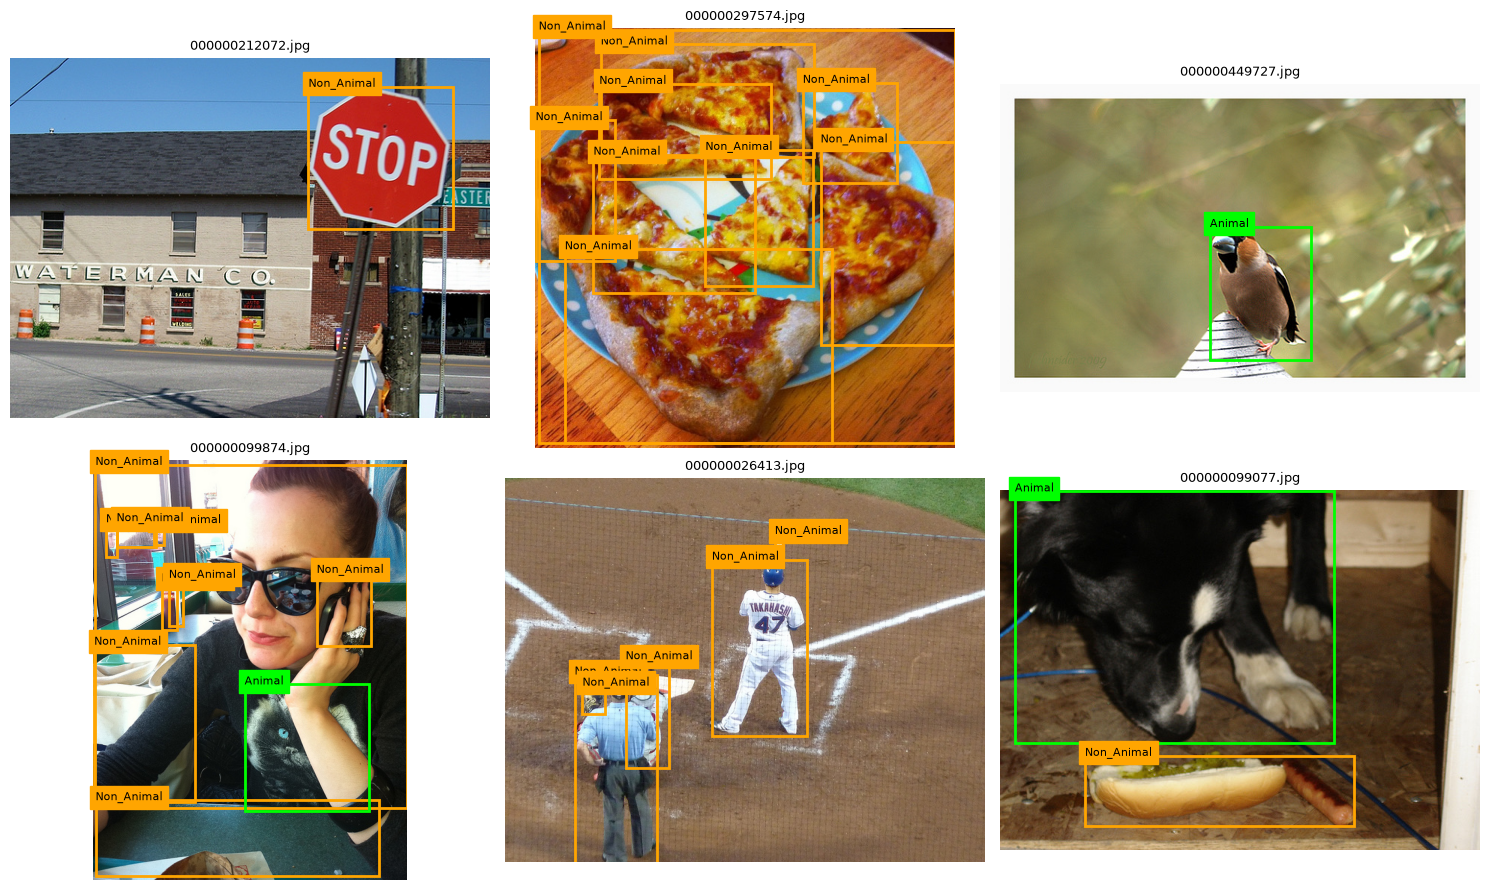

In [57]:
# ===================== 1F. VERIFICARE VIZUALĂ (recomandat!) =====================
# Desenăm etichetele pe câteva imagini ca să ne asigurăm că setul de date e corect.
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

CULORI = {0: "orange", 1: "lime"}

def arata_etichete(n=6):
    imgs = random.sample(sorted((DATASET / "images" / "train").glob("*.jpg")), n)
    fig, axe = plt.subplots(2, 3, figsize=(15, 9))
    for ax, img_path in zip(axe.flat, imgs):
        img = Image.open(img_path)
        W, H = img.size
        ax.imshow(img); ax.axis("off"); ax.set_title(img_path.name, fontsize=9)
        lbl = DATASET / "labels" / "train" / f"{img_path.stem}.txt"
        for linie in lbl.read_text().splitlines():
            c, x, y, w, h = linie.split(); c = int(c)
            x, y, w, h = float(x) * W, float(y) * H, float(w) * W, float(h) * H
            ax.add_patch(patches.Rectangle((x - w/2, y - h/2), w, h, fill=False, color=CULORI[c], lw=2))
            ax.text(x - w/2, y - h/2, CLASE[c], color="black", fontsize=8, backgroundcolor=CULORI[c])
    plt.tight_layout(); plt.show()

arata_etichete()

### (Optional) Alternative: use a Roboflow dataset instead
On [Roboflow Universe](https://universe.roboflow.com) you can search for datasets (e.g. *"animals"*, *"household objects"*),
click **Download Dataset → Format: YOLOv8 → Show download code**, and you get a snippet with your own API key.
Those datasets have their *own* class names, so they must be re-mapped to our 2 classes.
The function below does that for any YOLOv8-format folder: give it the folder and the list of names that count as animals.
**Skip this cell if you used the COCO steps above** (they're enough).

In [20]:
# ===================== (OPȚIONAL) RE-MAPARE PENTRU UN SET DESCĂRCAT DE PE ROBOFLOW =====================
# Exemplu de descărcare (codul exact îl copiezi de pe site, cu cheia ta API):
#   %pip install roboflow
#   from roboflow import Roboflow
#   rf = Roboflow(api_key="CHEIA_TA")
#   ds = rf.workspace("...").project("...").version(1).download("yolov8")

def remapeaza_set_roboflow(folder_set, nume_animale, folder_destinatie=DATASET):
    """Copiază un set YOLOv8 (train/valid/test) în DATASET, convertind clasele la 0/1."""
    folder_set = Path(folder_set)
    nume = yaml.safe_load((folder_set / "data.yaml").read_text())["names"]
    if isinstance(nume, dict):
        nume = [nume[k] for k in sorted(nume)]
    animale = {i for i, n in enumerate(nume) if n.lower() in {a.lower() for a in nume_animale}}
    print("Clase considerate Animal:", [nume[i] for i in animale])
    for split_src, split_dst in (("train", "train"), ("valid", "val"), ("test", "val")):
        for img in (folder_set / split_src / "images").glob("*.*"):
            lbl = folder_set / split_src / "labels" / f"{img.stem}.txt"
            linii = []
            if lbl.exists():
                for l in lbl.read_text().splitlines():
                    p = l.split()
                    if len(p) >= 5:
                        linii.append(" ".join(["1" if int(p[0]) in animale else "0"] + p[1:5]))
            shutil.copy2(img, folder_destinatie / "images" / split_dst / f"rf_{img.name}")
            (folder_destinatie / "labels" / split_dst / f"rf_{img.stem}.txt").write_text("\n".join(linii))
    print("✔ Set Roboflow adăugat în", folder_destinatie)

# remapeaza_set_roboflow("Calea/Catre/SetulRoboflow", ["dog", "cat", "horse", "bird"])

---
## Step 2 – Train YOLOv8 for the 2 classes

We start from **pretrained weights** (`yolov8n.pt` / `yolov8s.pt`, downloaded automatically) — this is *transfer learning*:
the model already knows how to see shapes and objects, we only teach it our 2 classes. It's much faster and more accurate
than training from zero.

The settings are chosen automatically based on whether you have a GPU:

| | Model | Epochs | Batch | Approx. time (≈8 000 images) |
|---|---|---|---|---|
| **GPU** (e.g. RTX 3060) | `yolov8s.pt` | 60 | auto | ~1–2 hours |
| **CPU** | `yolov8n.pt` | 25 | 8 | many hours (try `EXTRA_TRAIN_IMG = 0` and `imgsz=480` first) |

You will see a table that updates each epoch. Look at **mAP50** — it goes from 0 to 1; above **0.6** is good for this task.
Training stops by itself early if it stops improving (`patience`).

In [21]:
# ===================== PASUL 2: ANTRENAREA MODELULUI YOLOv8 =====================
import torch
from ultralytics import YOLO

# --- Detectăm automat dacă avem GPU și alegem setări potrivite ---
ARE_GPU = torch.cuda.is_available()
DEVICE  = 0 if ARE_GPU else "cpu"

# Modelul de pornire: "s" (small) e mai precis, "n" (nano) e mai rapid -> potrivit pentru CPU
MODEL_START = "yolov8s.pt" if ARE_GPU else "yolov8n.pt"
EPOCI       = 60 if ARE_GPU else 25
BATCH       = -1 if ARE_GPU else 8     # -1 = Ultralytics alege automat mărimea lotului după memoria GPU

model = YOLO(MODEL_START)              # se descarcă automat greutățile pre-antrenate pe COCO

rezultate = model.train(
    data=str(DATA_YAML),               # fișierul data.yaml creat la Pasul 1
    epochs=EPOCI,                      # de câte ori trece modelul prin toate imaginile
    imgsz=640,                         # mărimea imaginilor la antrenare (640 = standard YOLOv8)
    batch=BATCH,                       # câte imagini procesează deodată
    device=DEVICE,                     # 0 = prima placă video, "cpu" = procesor
    workers=2,                         # fire pentru încărcarea datelor; pe Windows, dacă se blochează, pune 0
    patience=15,                       # oprire automată dacă nu se îmbunătățește 15 epoci la rând
    optimizer="auto",                  # Ultralytics alege optimizatorul (SGD/AdamW) și rata de învățare
    cos_lr=True,                       # rata de învățare scade lin (cosinus) -> convergență mai stabilă
    single_cls=False,                  # IMPORTANT: păstrăm cele 2 clase separate (nu le unim)
    # --- Augmentări (variații ale imaginilor ca modelul să generalizeze mai bine) ---
    mosaic=1.0,                        # combină 4 imagini într-una -> multe obiecte mici, foarte util
    close_mosaic=10,                   # oprim mosaic în ultimele 10 epoci pentru finisare pe imagini reale
    mixup=0.1,                         # suprapune ușor două imagini -> robustețe
    fliplr=0.5,                        # oglindire stânga-dreapta (un câine oglindit tot câine e)
    flipud=0.0,                        # fără răsturnare sus-jos (animalele nu stau cu capul în jos)
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, # variații de culoare/saturație/luminozitate
    degrees=0.0, scale=0.5, translate=0.1,
    amp=ARE_GPU,                       # precizie mixtă pe GPU -> mai rapid, mai puțină memorie
    cache=False,                       # True = ține imaginile în RAM (mai rapid, dar consumă mult)
    plots=True,                        # salvează grafice: curbe de pierdere, matricea de confuzie etc.
    project=str(PROIECT / "runs"),     # unde se salvează rezultatele
    name="animal_vs_non_animal",
    exist_ok=True,                     # suprascrie folderul dacă rulezi din nou
    seed=SEED,
)

# Calea către cel mai bun model salvat
BEST_PT = Path(rezultate.save_dir) / "weights" / "best.pt"
print("\n✔ Antrenare terminată! Cel mai bun model:", BEST_PT)

Ultralytics 8.4.203  Python-3.12.10 torch-2.14.1+cpu CPU (11th Gen Intel Core i5-11320H @ 3.20GHz)
engine\trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Lorena\Desktop\Proiecte personale\Animal_Detection\animal_project\dataset\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, mul

In [19]:
# ===================== PASUL 2B: CONTINUĂM ANTRENAREA (FINE-TUNING) =====================
import torch
from ultralytics import YOLO

DEVICE = 0 if torch.cuda.is_available() else "cpu"

# Pornim de la modelul deja antrenat, nu de la zero
BEST_VECHI = PROIECT / "runs" / "animal_vs_non_animal" / "weights" / "best.pt"
model = YOLO(str(BEST_VECHI))

rezultate = model.train(
    data=str(DATA_YAML),
    epochs=40,                  # încă 40 de epoci (curbele încă urcau la epoca 25)
    imgsz=640,
    batch=8,                    # potrivit pentru CPU
    device=DEVICE,
    workers=0,                  # 0 = cel mai sigur pe Windows în Jupyter (fără blocaje)
    patience=10,                # se oprește singur dacă nu mai progresează
    optimizer="AdamW",
    lr0=0.0005,                 # rată de învățare mică: rafinăm, nu reînvățăm de la zero
    warmup_epochs=1,
    cos_lr=True,
    mosaic=1.0, close_mosaic=10, mixup=0.1, fliplr=0.5,
    project=str(PROIECT / "runs"),
    name="animal_v2",           # rezultatele noi se salvează separat, modelul vechi rămâne intact
    exist_ok=True,
    seed=SEED,
)
BEST_PT = Path(rezultate.save_dir) / "weights" / "best.pt"
print("✔ Model nou:", BEST_PT)

New https://pypi.org/project/ultralytics/8.4.204 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.203  Python-3.12.10 torch-2.14.1+cpu CPU (11th Gen Intel Core i5-11320H @ 3.20GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Lorena\Desktop\Proiecte personale\Animal_Detection\animal_project\dataset\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.0

In [4]:
# ===================== PASUL 2C: MODEL MAI MARE (yolov8s) PE GPU =====================
import torch
from pathlib import Path
from ultralytics import YOLO

# Verificăm că GPU-ul e detectat, altfel ne oprim
assert torch.cuda.is_available(), "GPU-ul NU e detectat!"
print("Antrenăm pe:", torch.cuda.get_device_name(0))
DEVICE = 0

model = YOLO("yolov8s.pt")             # model nou, de ~3x mai mare decât yolov8n

rezultate = model.train(
    data=str(DATA_YAML),
    epochs=60,                         # suficient pentru un model bun
    imgsz=640,
    batch=-1,                          # alege automat lotul după cei 4 GB ai plăcii
    device=DEVICE,                     # 0 = placa NVIDIA
    workers=2,                         # dacă se blochează la început, pune 0
    patience=15,                       # oprire automată dacă nu mai progresează
    optimizer="auto",
    cos_lr=True,
    mosaic=1.0, close_mosaic=10, mixup=0.1, fliplr=0.5,
    amp=True,                          # mai rapid și mai puțină memorie pe GPU
    project=str(PROIECT / "runs"),
    name="animal_gpu_s",               # FOLDER NOU: modelele vechi rămân neatinse
    exist_ok=True,
    seed=SEED,
)
BEST_PT = Path(rezultate.save_dir) / "weights" / "best.pt"
print("✔ Model GPU:", BEST_PT)

Antrenăm pe: NVIDIA GeForce RTX 3050 Ti Laptop GPU
New https://pypi.org/project/ultralytics/8.4.207 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.203  Python-3.12.10 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Lorena\Desktop\Proiecte personale\Animal_Detection\animal_project\dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz

In [58]:
# ===================== PASUL 2D: ANTRENARE CU MAI MULTE POZE (GPU, ~3.3 ore) =====================
import torch
from pathlib import Path
from ultralytics import YOLO

assert torch.cuda.is_available(), "GPU-ul NU e detectat!"
DEVICE = 0

# Pornim de la cel mai bun model de până acum (cel de pe GPU), ca să ne încadrăm în timp
model = YOLO(str(PROIECT / "runs" / "animal_gpu_s" / "weights" / "best.pt"))

rezultate = model.train(
    data=str(DATA_YAML),
    epochs=30,
    imgsz=640,
    batch=-1,
    device=DEVICE,
    workers=2,
    patience=10,
    optimizer="AdamW",
    lr0=0.0005,
    warmup_epochs=1,
    cos_lr=True,
    mosaic=1.0, close_mosaic=10, mixup=0.1, fliplr=0.5,
    amp=True,
    project=str(PROIECT / "runs"),
    name="animal_gpu_mare",            # FOLDER NOU: celelalte modele rămân neatinse
    exist_ok=True,
    seed=SEED,
)
BEST_PT = Path(rezultate.save_dir) / "weights" / "best.pt"
print("✔ Model final:", BEST_PT)

New https://pypi.org/project/ultralytics/8.4.207 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.203  Python-3.12.10 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Lorena\Desktop\Proiecte personale\Animal_Detection\animal_project\dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.000

In [60]:
# ===================== EVALUARE PE SETUL DE VALIDARE =====================
# Calculăm acuratețea finală pentru fiecare clasă
best_model = YOLO(str(BEST_PT))
metrici = best_model.val(data=str(DATA_YAML), device=DEVICE, workers=2, plots=False)

print(f"\nmAP50 total      : {metrici.box.map50:.3f}")
print(f"mAP50-95 total   : {metrici.box.map:.3f}")
for i, nume in CLASE.items():
    print(f"  {nume:11s} -> mAP50-95: {metrici.box.maps[i]:.3f}")

Ultralytics 8.4.203  Python-3.12.10 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce RTX 3050 Ti Laptop GPU, 4096MiB)
Model summary (fused): 72 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1004.5±455.6 MB/s, size: 160.9 KB)
val: Scanning C:\Users\Lorena\Desktop\Proiecte personale\Animal_Detection\animal_project\dataset\labels\val.cache... 750 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 750/750  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 47/47 3.9it/s 12.1s0.1s
                   all        750       5648      0.744      0.572      0.647      0.455
            Non_Animal        673       5306      0.714      0.422      0.533      0.344
                Animal        142        342      0.774      0.722      0.762      0.567
Speed: 0.7ms preprocess, 7.1ms inference, 0.0ms loss, 0.8ms postprocess per image

mAP50 total      : 0.647
mAP50-95 total   : 0.455
  No

results.png


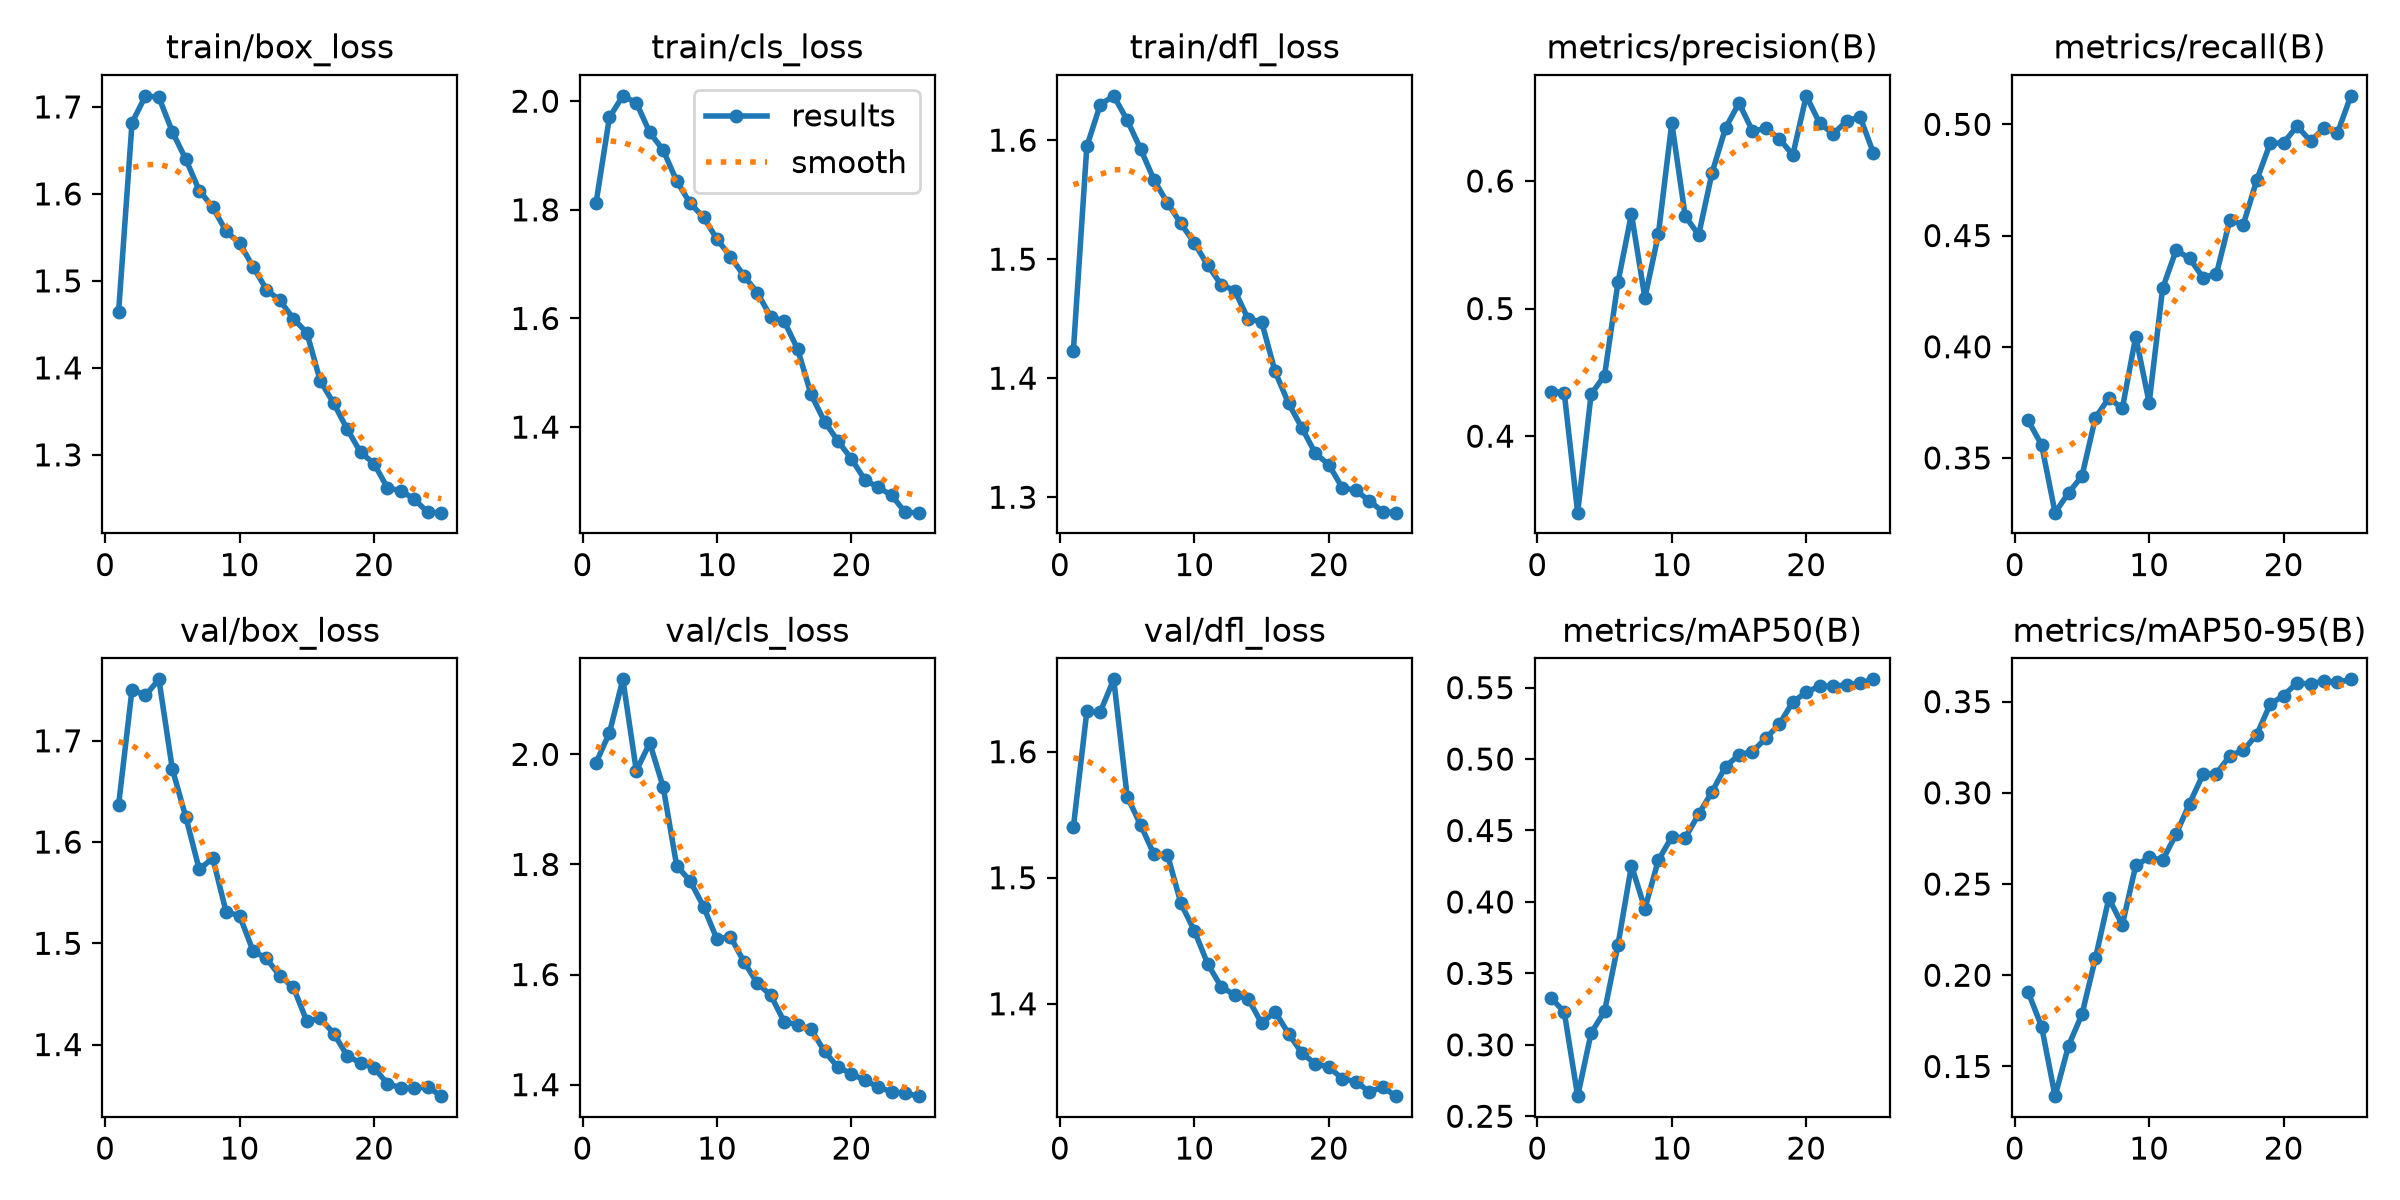

confusion_matrix_normalized.png


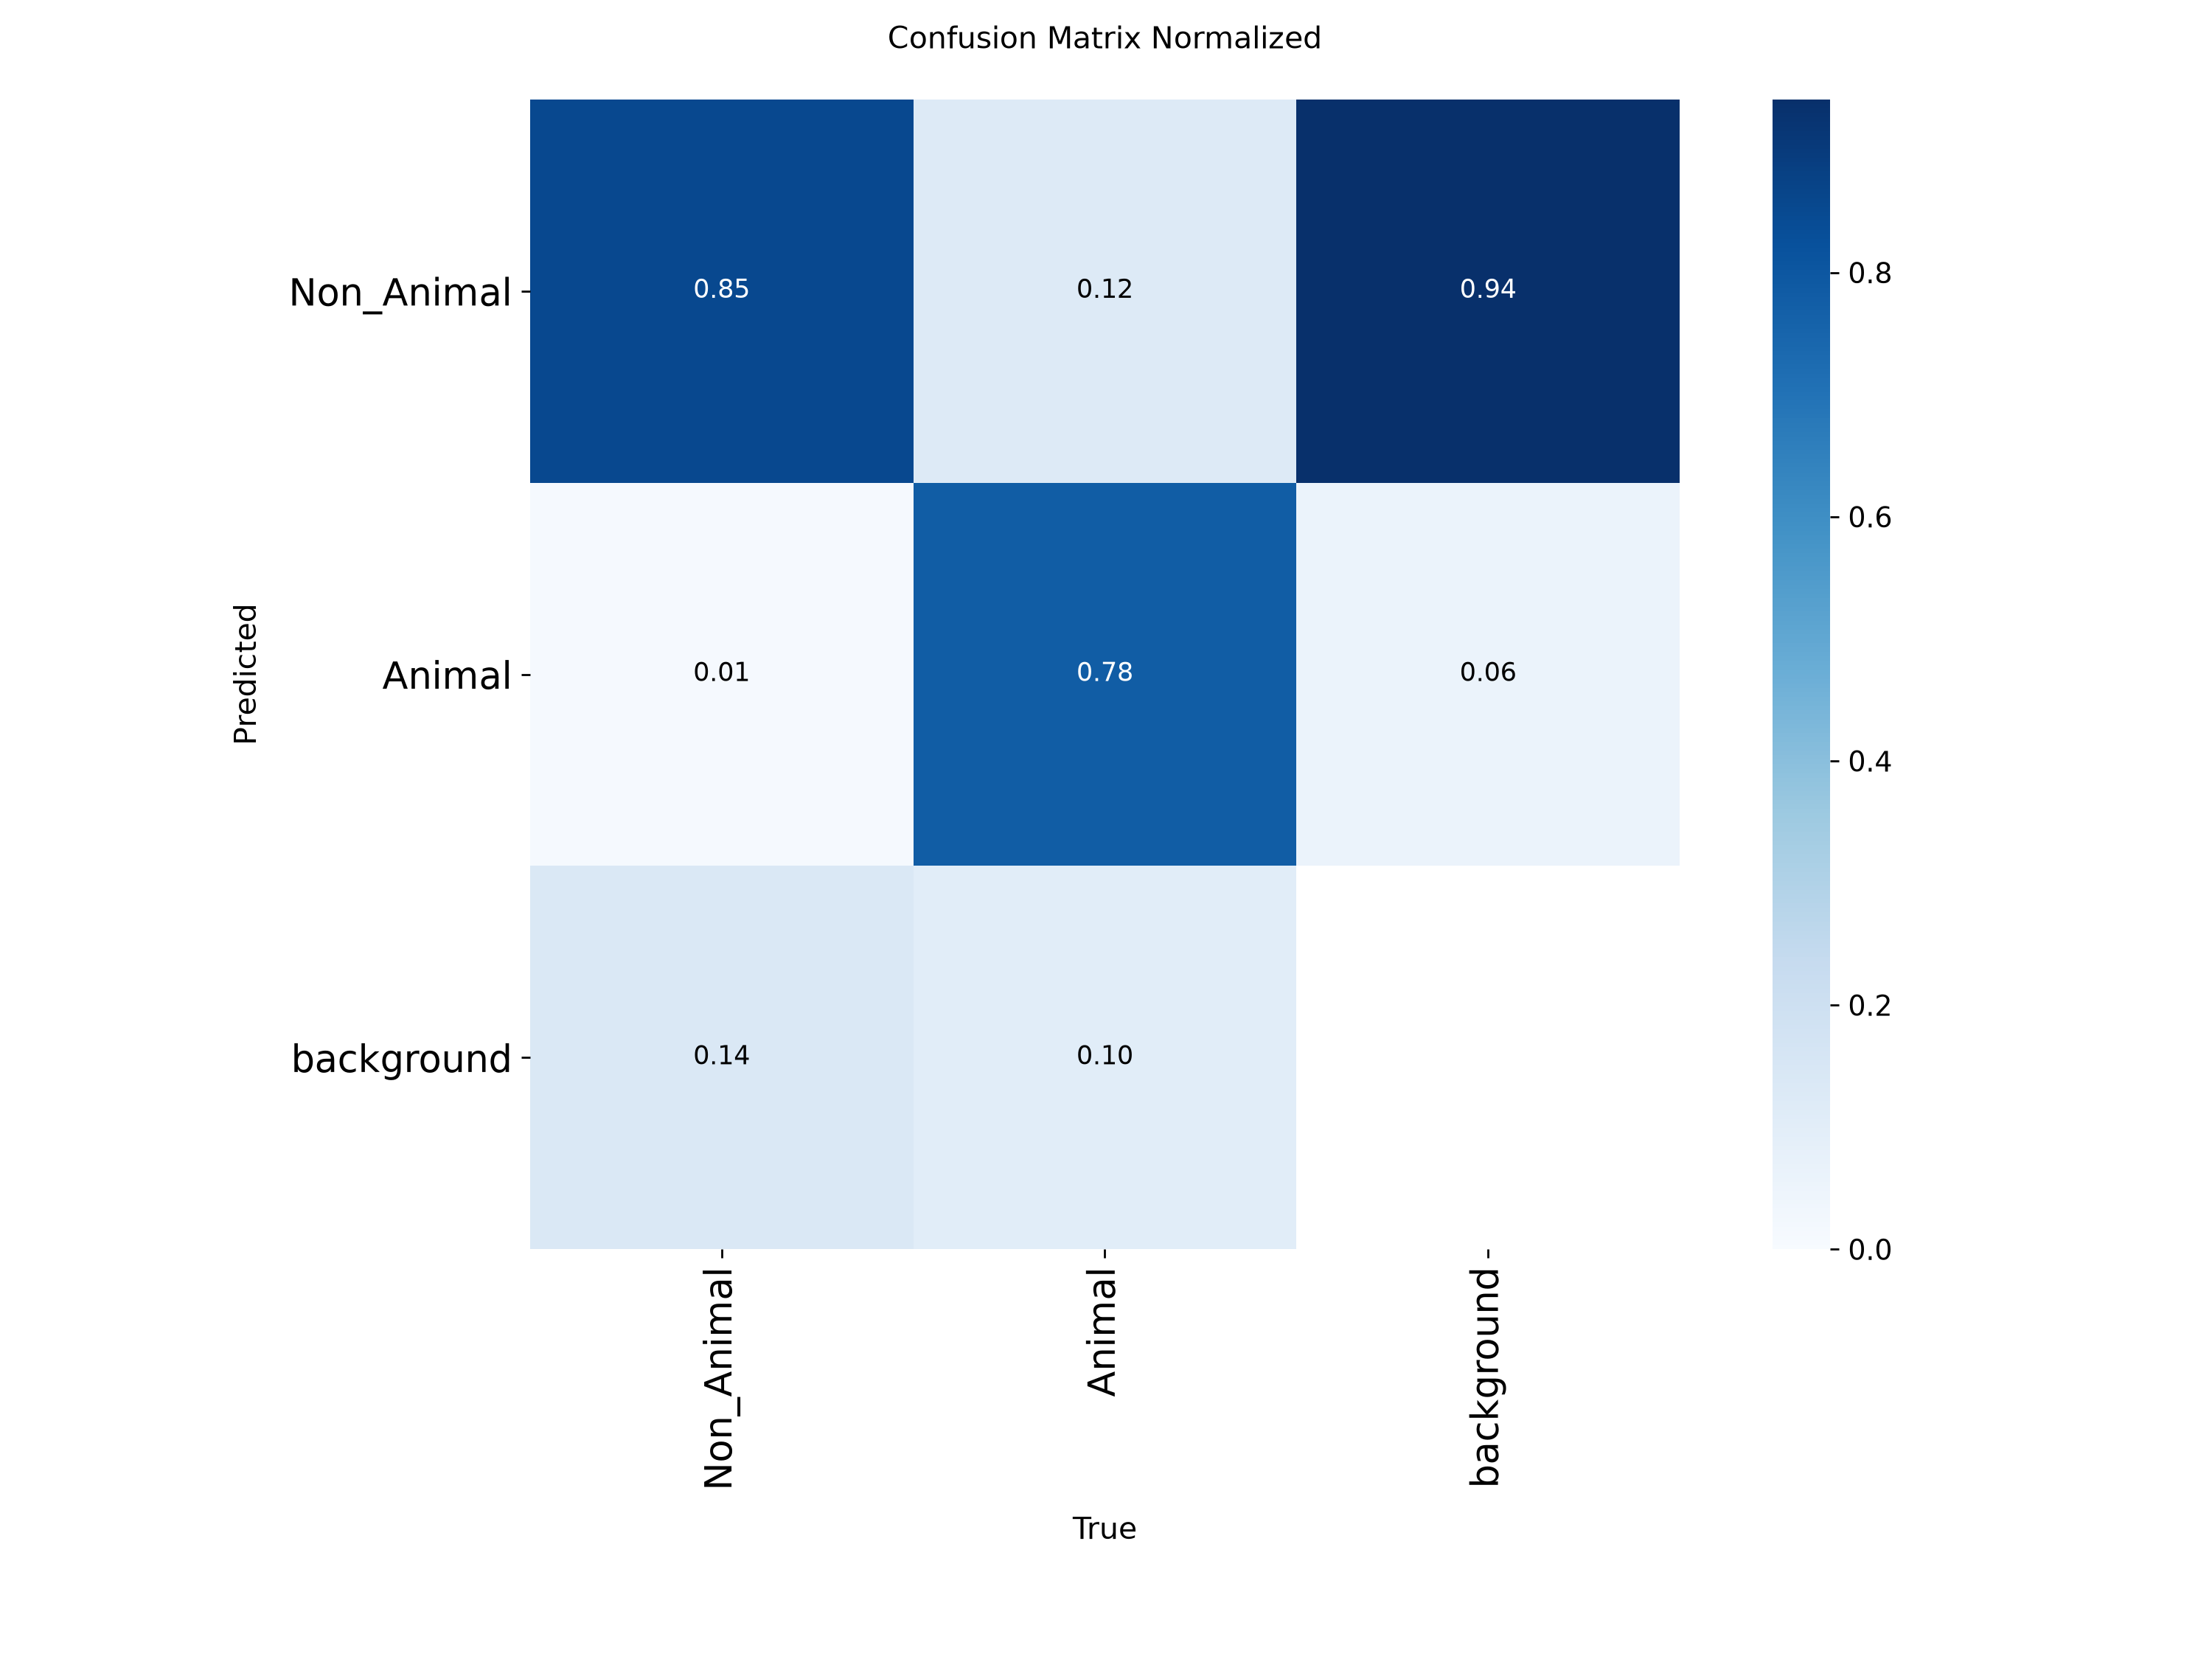

In [23]:
ZS

results.png


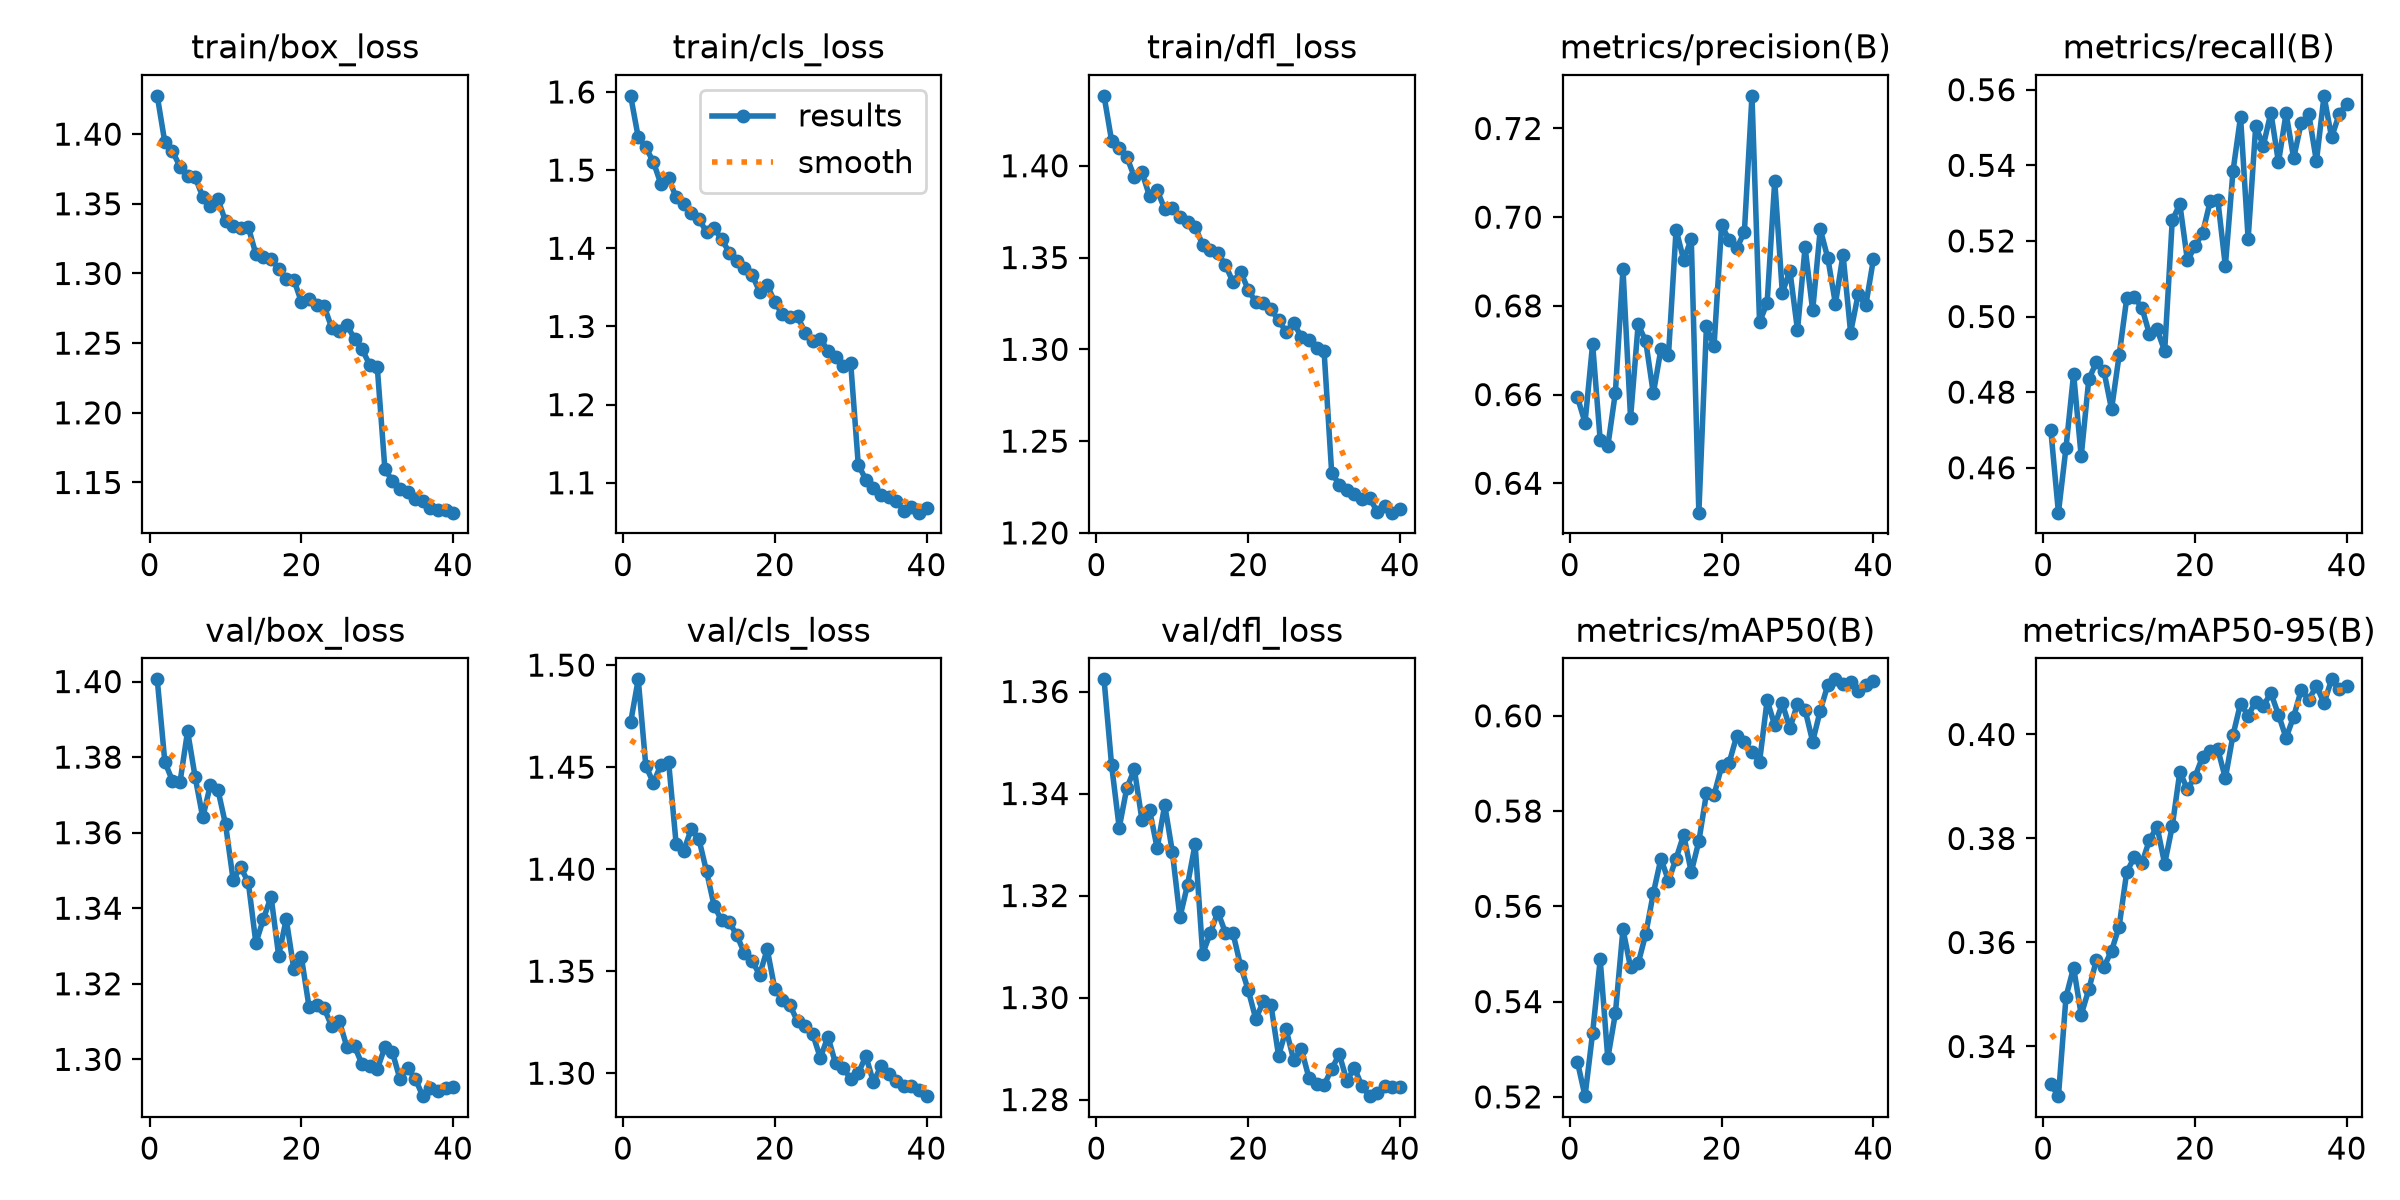

confusion_matrix_normalized.png


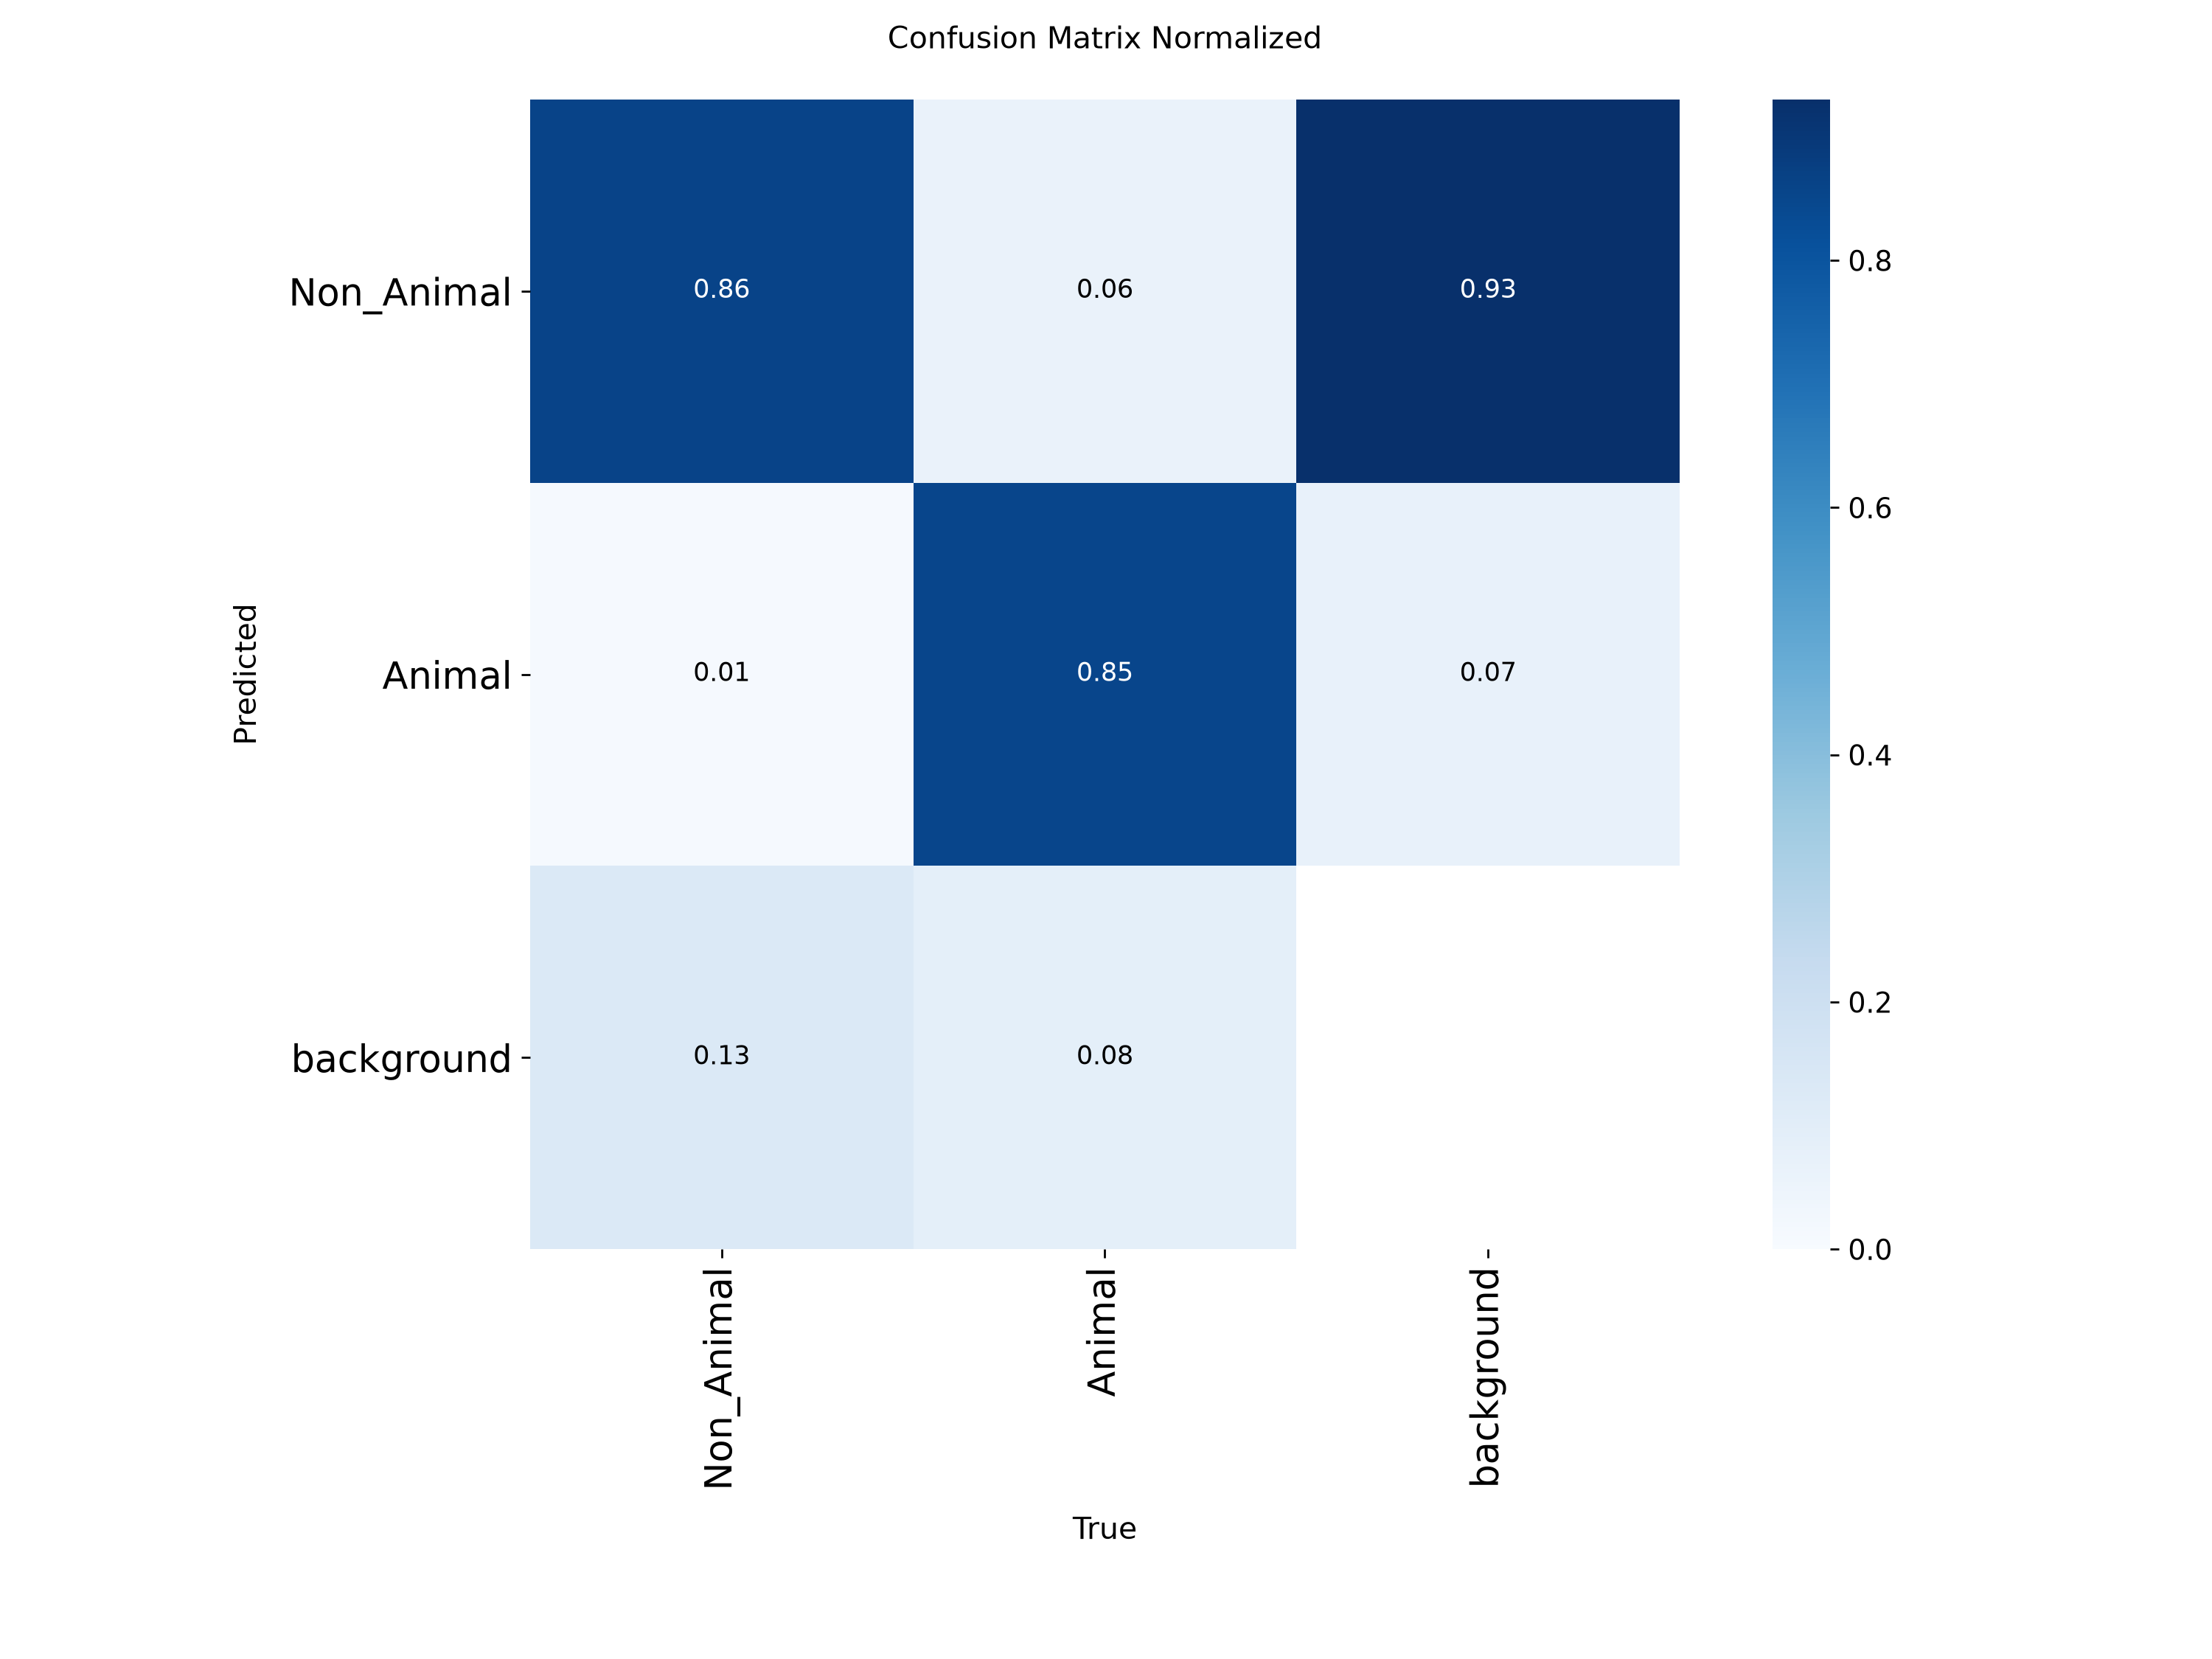

In [21]:
# ===================== GRAFICELE ANTRENĂRII =====================
# Afișăm graficele modelului NOU (animal_v2)
from IPython.display import Image as IPyImage, display
from pathlib import Path

folder = Path.cwd() / "animal_project" / "runs" / "animal_v2"
for fisier in ("results.png", "confusion_matrix_normalized.png"):
    cale = folder / fisier
    if cale.exists():
        print(fisier); display(IPyImage(filename=str(cale), width=900))
    else:
        print("Nu găsesc:", cale)

results.png


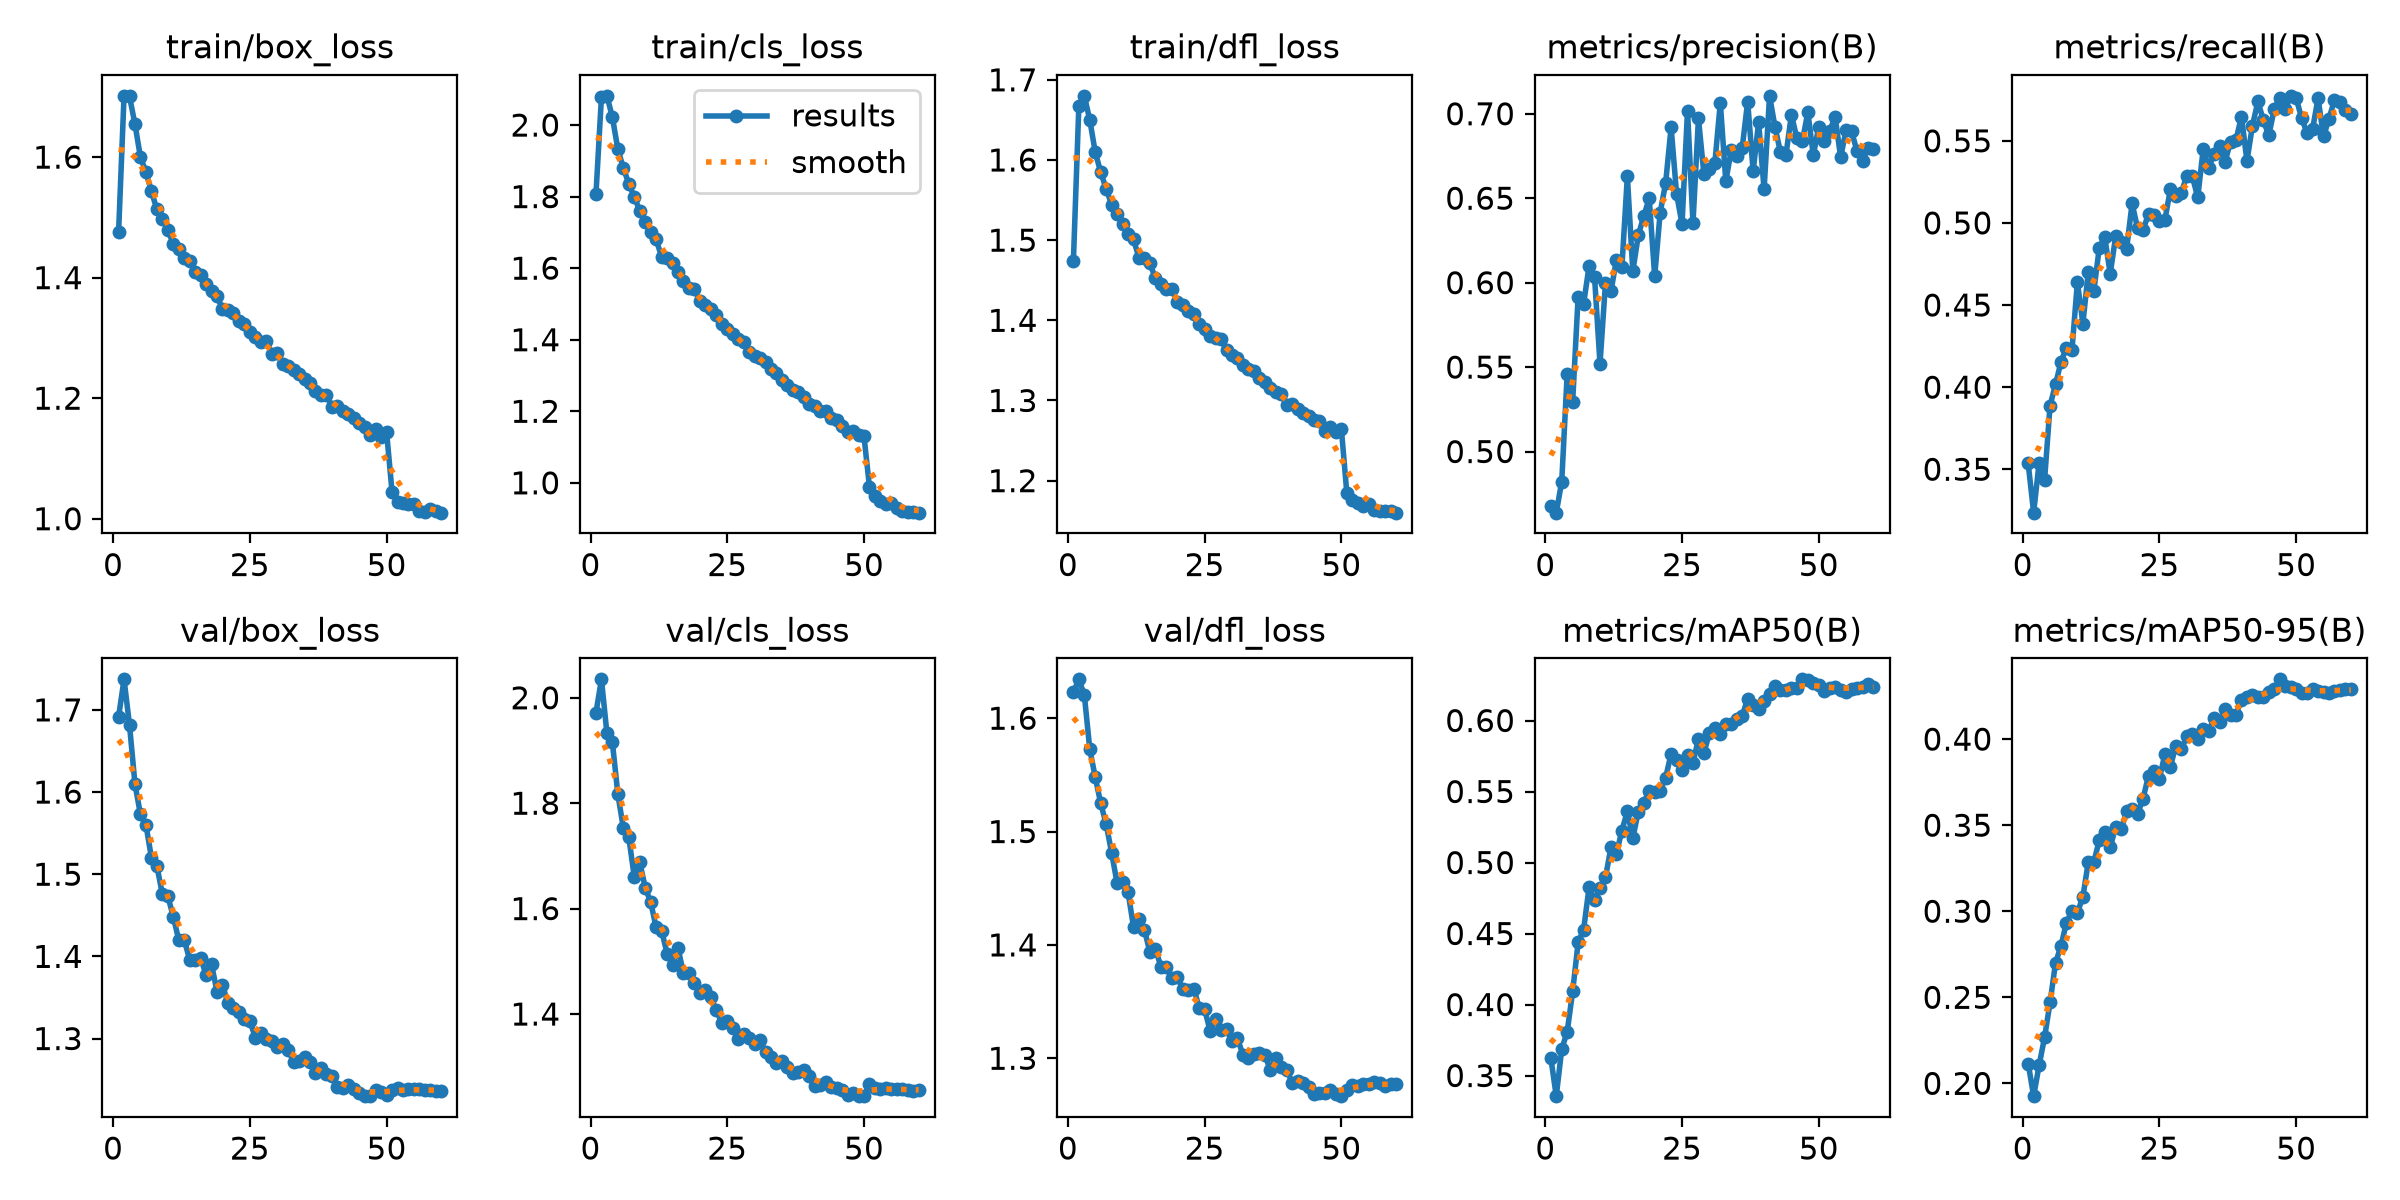

confusion_matrix_normalized.png


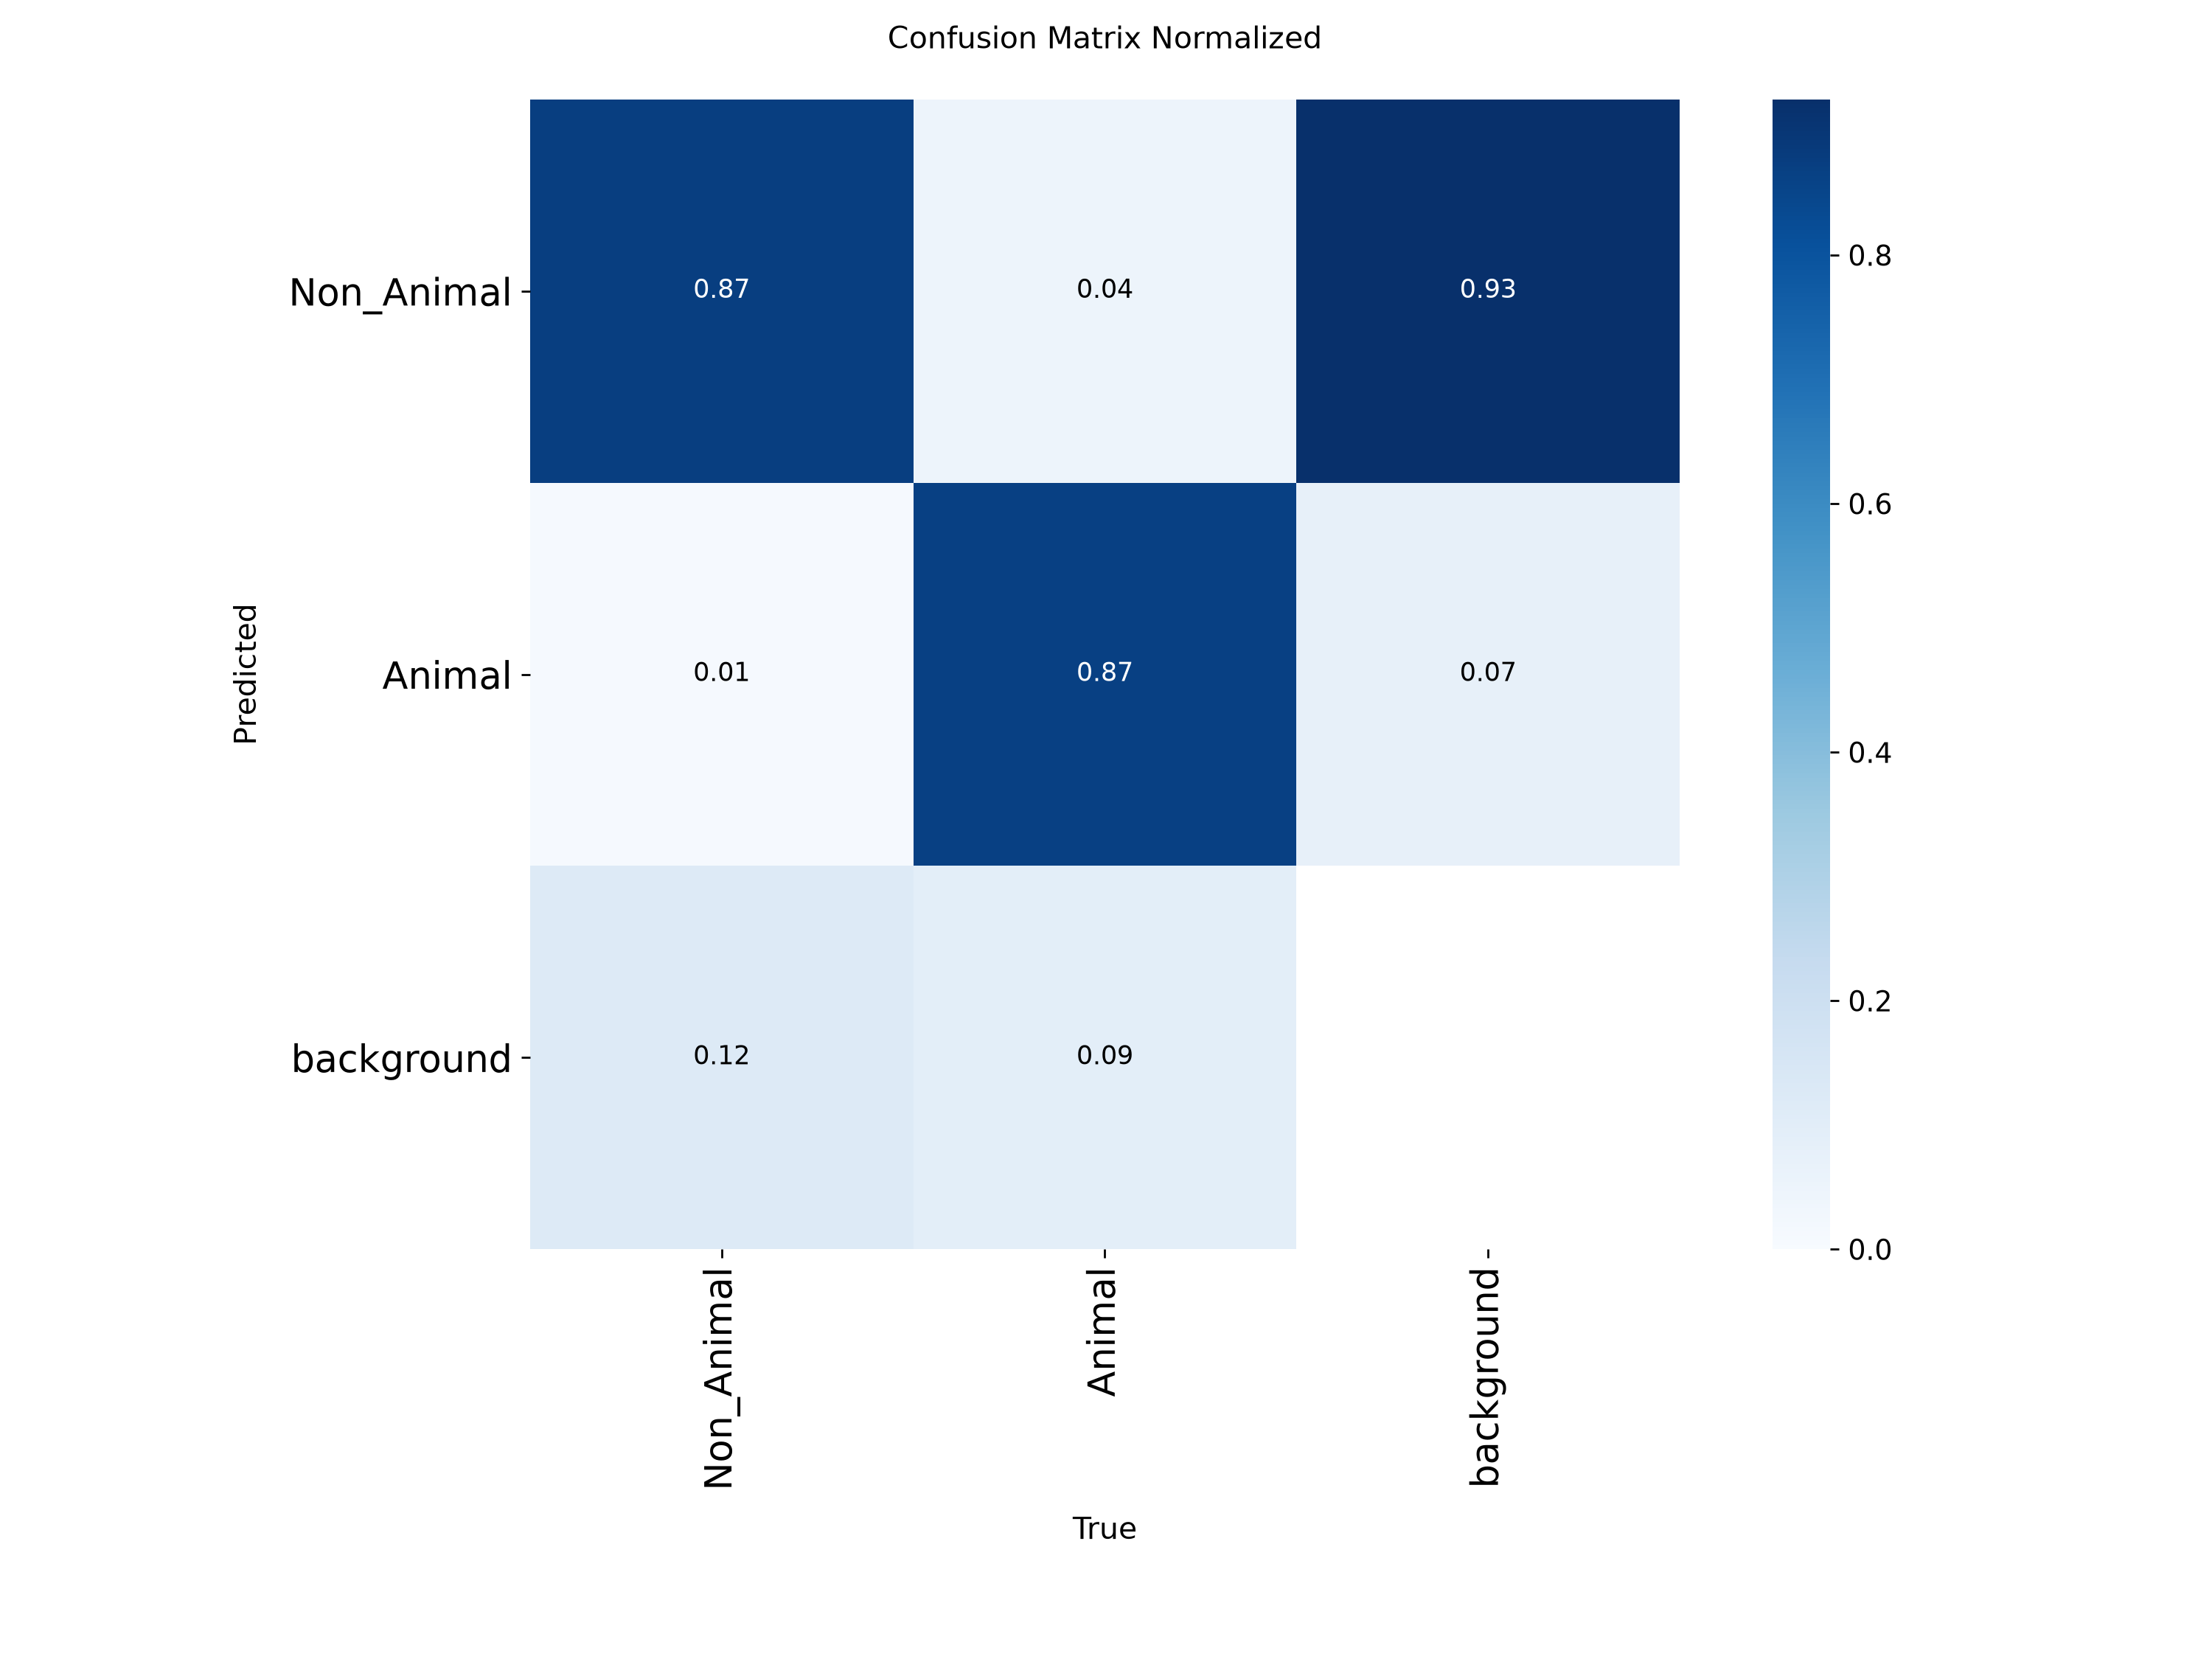

In [5]:
# ===================== GRAFICELE ANTRENĂRII =====================
# Afișăm graficele modelului NOU (animal_gpu_s)
from IPython.display import Image as IPyImage, display
from pathlib import Path

folder = Path.cwd() / "animal_project" / "runs" / "animal_gpu_s"
for fisier in ("results.png", "confusion_matrix_normalized.png"):
    cale = folder / fisier
    if cale.exists():
        print(fisier); display(IPyImage(filename=str(cale), width=900))
    else:
        print("Nu găsesc:", cale)

results.png


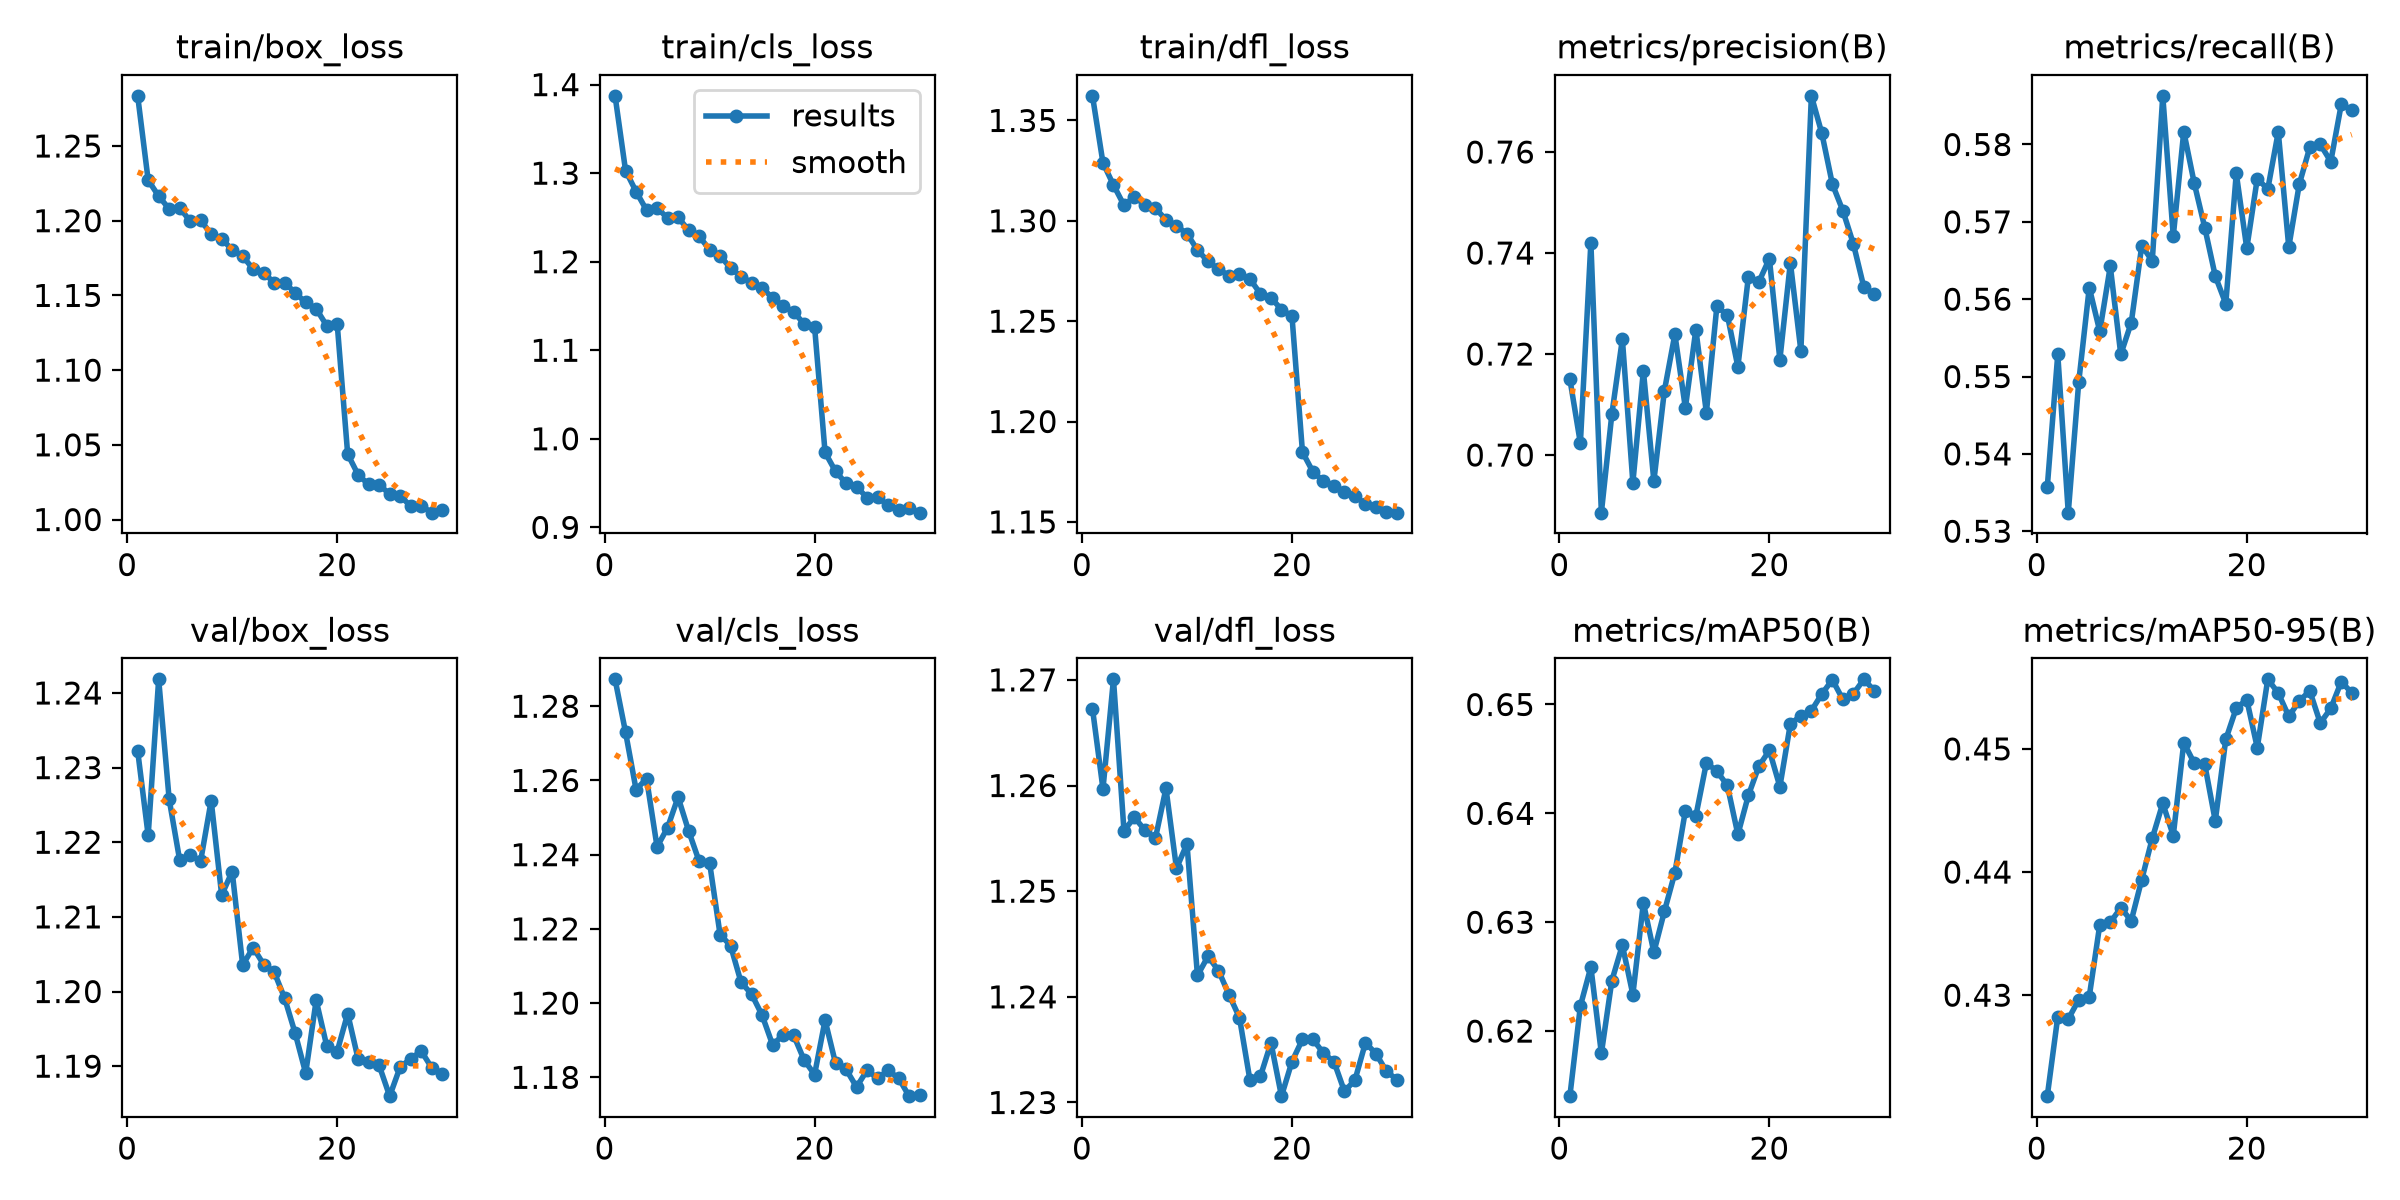

confusion_matrix_normalized.png


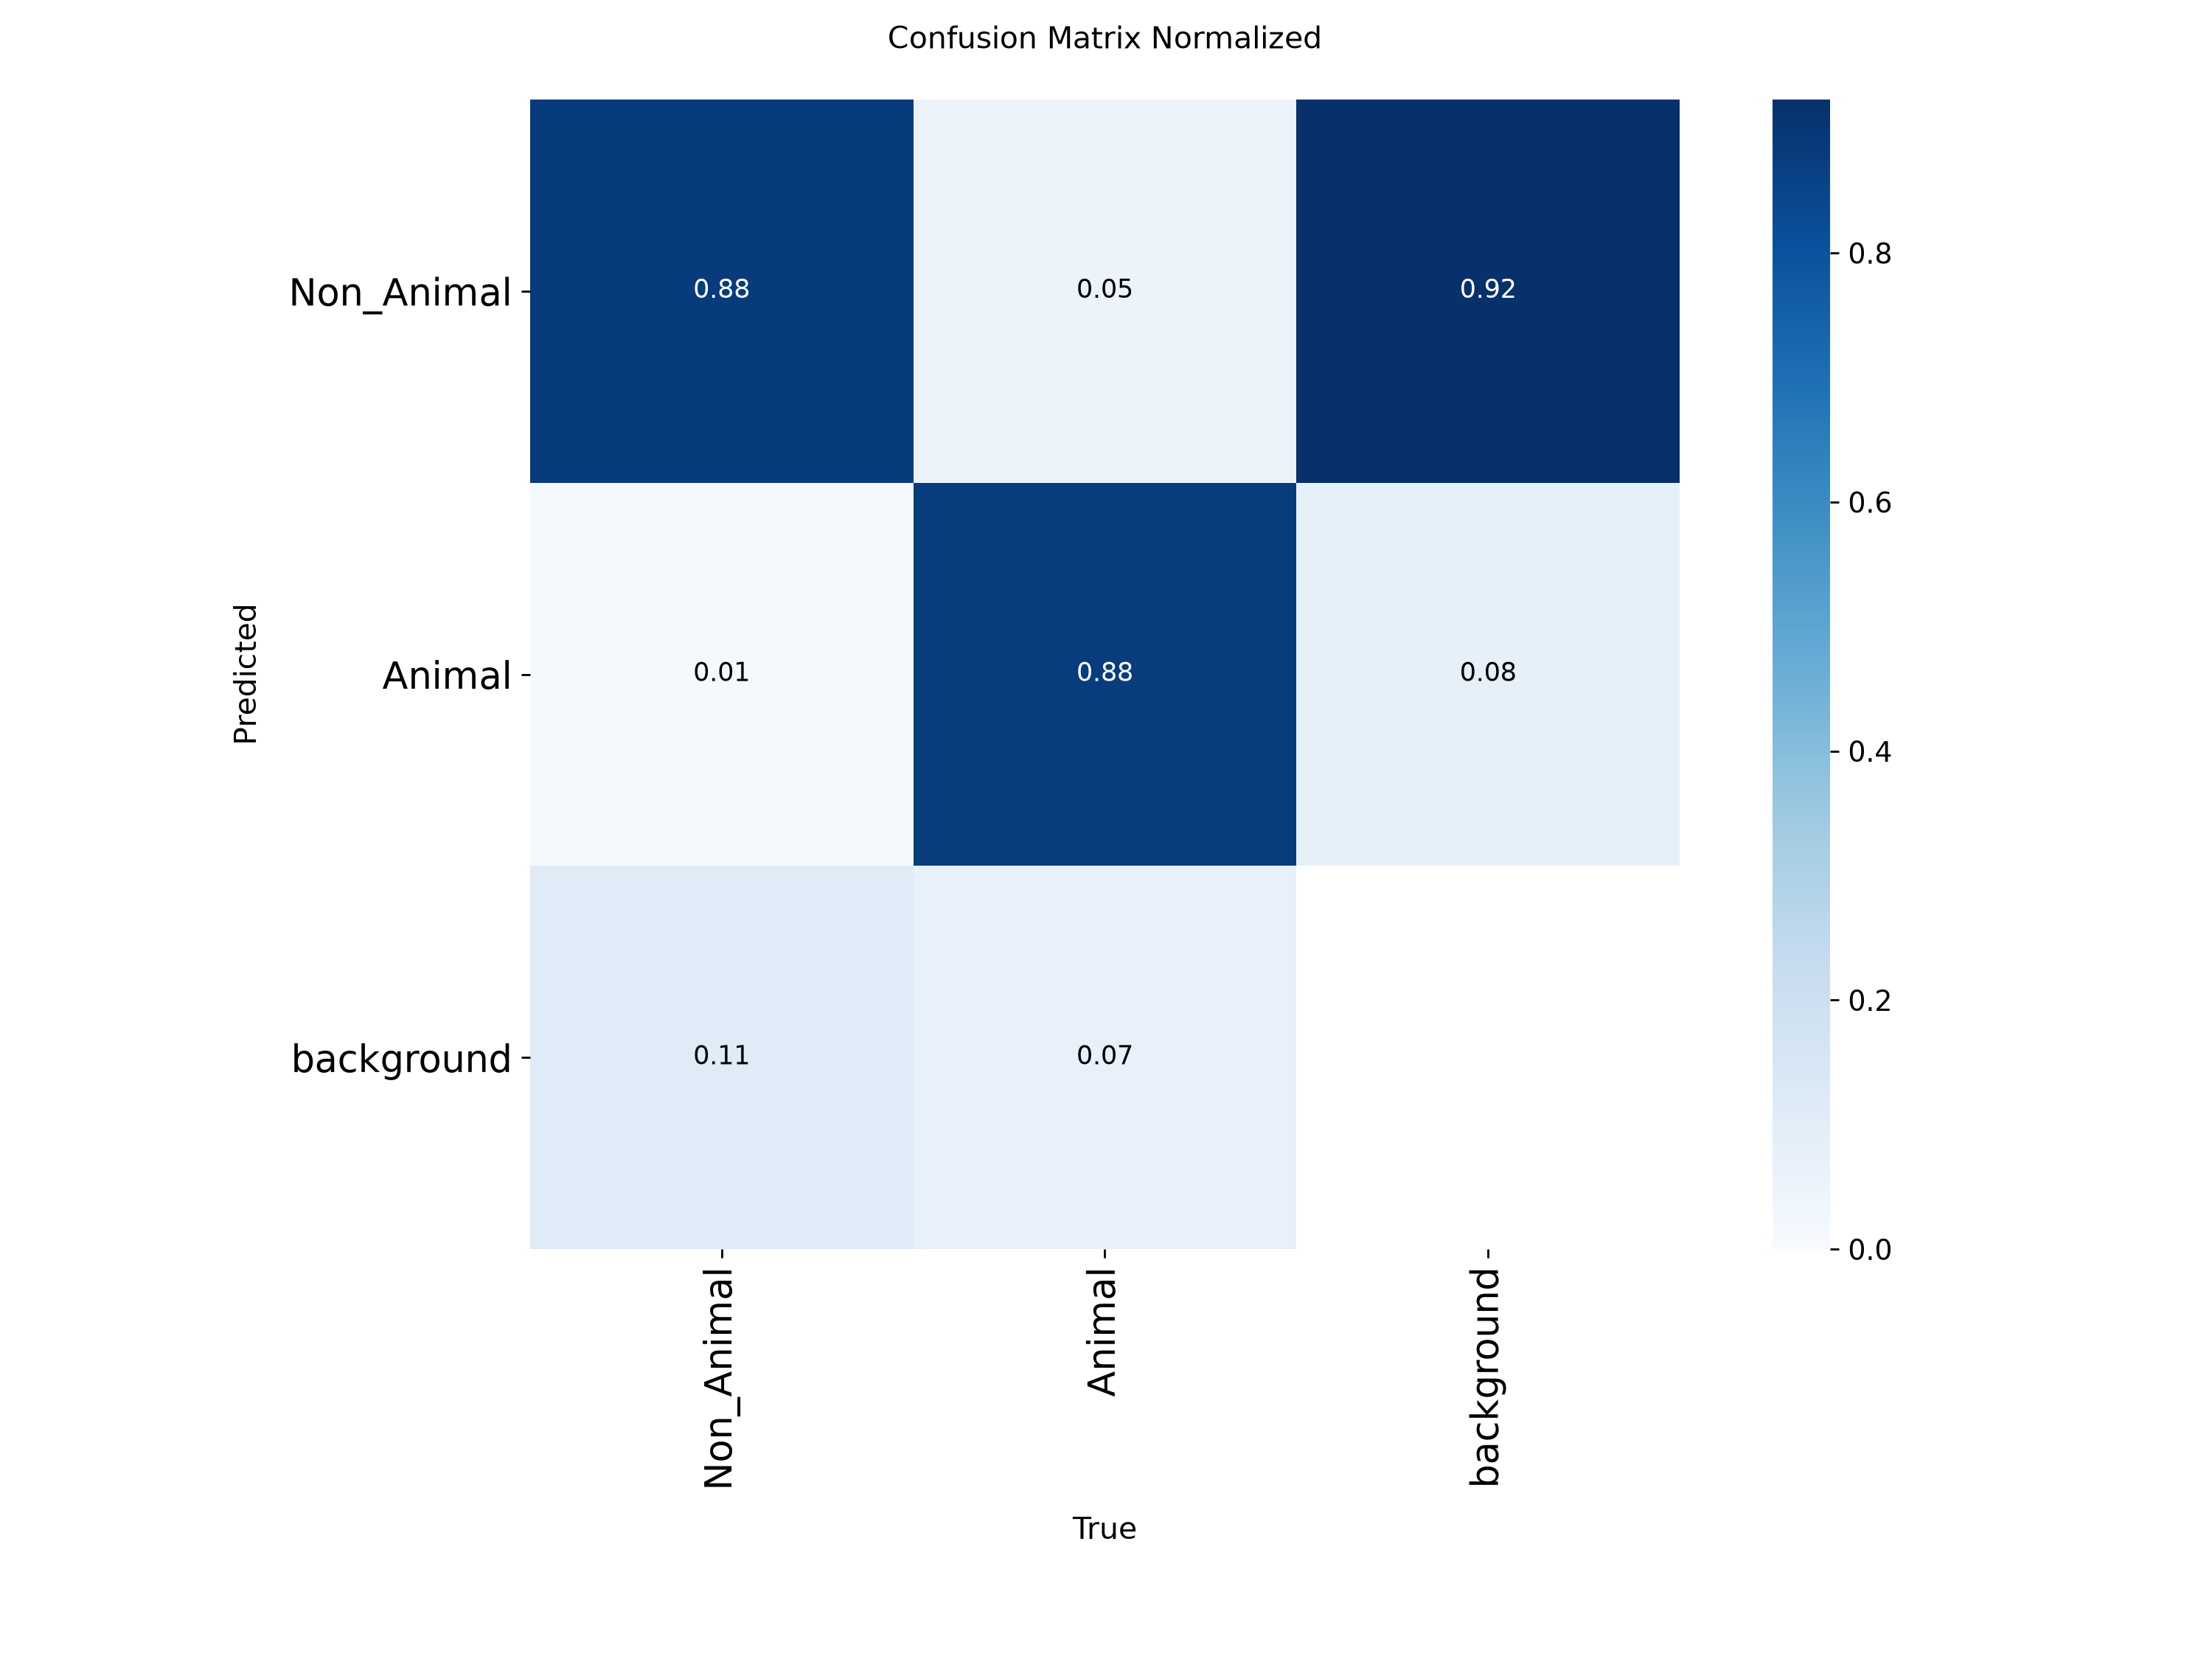

In [61]:
# ===================== GRAFICELE ANTRENĂRII =====================
# Afișăm graficele modelului NOU (animal_gpu_mare)
from IPython.display import Image as IPyImage, display
from pathlib import Path

folder = Path.cwd() / "animal_project" / "runs" / "animal_gpu_mare"
for fisier in ("results.png", "confusion_matrix_normalized.png"):
    cale = folder / fisier
    if cale.exists():
        print(fisier); display(IPyImage(filename=str(cale), width=900))
    else:
        print("Nu găsesc:", cale)

---
## Step 3 – Test on a new image and count automatically

Put any photo (e.g. a cat next to a remote) somewhere on your computer and set `IMAGINE_TEST` to its path.
On Windows, write the path with an `r` in front so the backslashes work: `r"C:\Users\Ana\Pictures\pisica.jpg"`.
You can also give an internet link (`https://...jpg`).

> ✅ **This step works on its own**: after training once, you can restart JupyterLab later and run *only* Step 3 —
> just make sure `CALE_MODEL` points to your `best.pt`.

Model folosit: C:\Users\Lorena\Desktop\Proiecte personale\Animal_Detection\animal_project\runs\animal_gpu_mare\weights\best.pt
Poză: groza.png


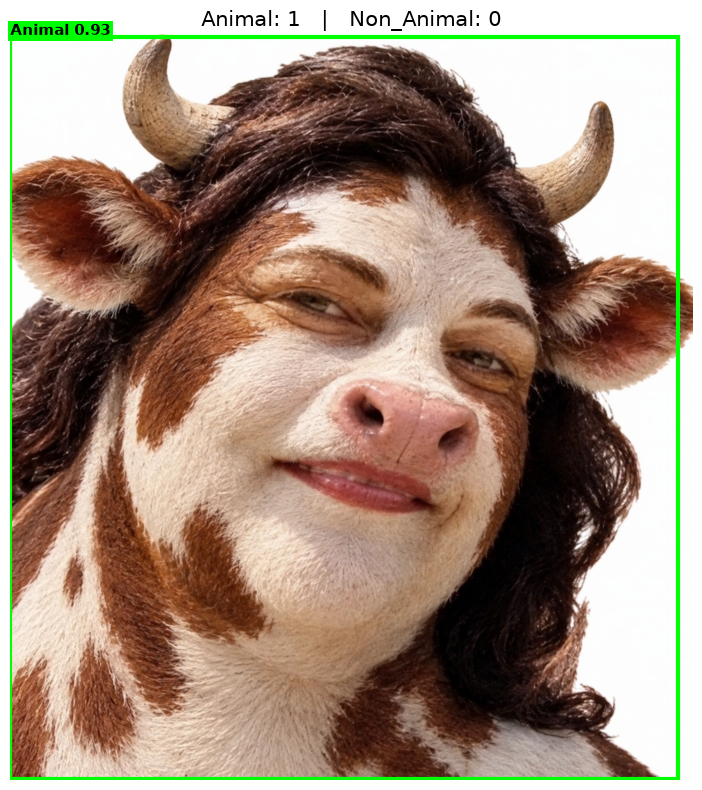

Number of animals detected: 1
Number of non-animal objects detected: 0


In [73]:
# ===================== PASUL 3: TESTARE + NUMĂRARE AUTOMATĂ =====================
from pathlib import Path
from collections import Counter
import io, random, requests, torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO

# --- Alegem modelul: cel FINAL primul, apoi celelalte (doar dacă cel final lipsește) ---
RUNS = Path.cwd() / "animal_project" / "runs"
CALE_MODEL = next(p for p in [RUNS / "animal_gpu_mare" / "weights" / "best.pt",
                              RUNS / "animal_gpu_s" / "weights" / "best.pt",
                              RUNS / "animal_v2" / "weights" / "best.pt",
                              RUNS / "animal_vs_non_animal" / "weights" / "best.pt"] if p.exists())
print("Model folosit:", CALE_MODEL)

DEVICE_TEST = 0 if torch.cuda.is_available() else "cpu"     # folosim placa video dacă există
PRAG_INCREDERE = 0.5        # doar detecțiile cu încredere >= 50% sunt desenate și numărate

# --- Toate pozele de test (poze nevăzute la antrenare) ---
POZE_TEST = list((Path.cwd() / "animal_project" / "dataset" / "images" / "val").glob("*.jpg"))

CULORI = {0: "orange", 1: "lime"}            # Non_Animal = portocaliu, Animal = verde

model_test = YOLO(str(CALE_MODEL))
NUME_CLASE = model_test.names                 # {0: 'Non_Animal', 1: 'Animal'}

def incarca_imagine(sursa):
    """Încarcă o imagine dintr-un fișier local sau de pe internet."""
    if str(sursa).startswith(("http://", "https://")):
        r = requests.get(sursa, timeout=30); r.raise_for_status()
        return Image.open(io.BytesIO(r.content)).convert("RGB")
    return Image.open(sursa).convert("RGB")

def detecteaza_si_numara(sursa, prag=PRAG_INCREDERE, arata=True):
    """Detectează obiectele, le desenează și le numără."""
    print("Poză:", Path(str(sursa)).name)
    img = incarca_imagine(sursa)
    rez = model_test.predict(img, conf=prag, device=DEVICE_TEST, verbose=False)[0]

    clase = rez.boxes.cls.int().tolist()
    scoruri = rez.boxes.conf.tolist()
    cutii = rez.boxes.xyxy.tolist()
    numar = Counter(clase)

    # --- Desenăm rezultatul cu matplotlib ---
    if arata:
        fig, ax = plt.subplots(figsize=(12, 8))
        ax.imshow(img); ax.axis("off")
        for (x1, y1, x2, y2), c, s in zip(cutii, clase, scoruri):
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color=CULORI[c], lw=3))
            ax.text(x1, y1 - 4, f"{NUME_CLASE[c]} {s:.2f}", color="black", fontsize=11,
                    fontweight="bold", bbox=dict(facecolor=CULORI[c], edgecolor="none", pad=2))
        ax.set_title(f"Animal: {numar.get(1, 0)}   |   Non_Animal: {numar.get(0, 0)}", fontsize=15)
        plt.tight_layout(); plt.show()

    # --- Afișăm numărătoarea ---
    print(f"Number of animals detected: {numar.get(1, 0)}")
    print(f"Number of non-animal objects detected: {numar.get(0, 0)}")
    return numar.get(1, 0), numar.get(0, 0)

# --- Testăm pe o poză aleasă LA ÎNTÂMPLARE ---
IMAGINE_TEST = random.choice(POZE_TEST)
# Ca să testezi o poză anume, scoate "#" din fața liniei de mai jos și pune calea ei:
animale, obiecte = detecteaza_si_numara( IMAGINE_TEST)

In [74]:
# ===================== BONUS: TESTARE PE UN FOLDER ÎNTREG =====================
# Rulează detecția pe toate imaginile dintr-un folder și afișează un rezumat
FOLDER_TEST = r"C:\Users\NumeleTau\Pictures\test"     # <-- schimbă cu folderul tău

total_a = total_o = 0
for img in sorted(Path(FOLDER_TEST).glob("*")):
    if img.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
        print(f"\n--- {img.name} ---")
        a, o = detecteaza_si_numara(img, arata=False)
        total_a += a; total_o += o
print(f"\nTOTAL -> Animals: {total_a} | Non-animal objects: {total_o}")


TOTAL -> Animals: 0 | Non-animal objects: 0


---
## 💡 Tips for a first-time YOLO project

**Before you start**
- Install **Anaconda** or plain Python 3.12, then `pip install jupyterlab` and start it with `jupyter lab` from a folder
  you'll keep the project in (e.g. `C:\Projects\animals`). Avoid folders inside OneDrive — syncing slows everything down.
- Avoid spaces and diacritics (ă, ș, ț) in folder paths if you can; some tools still trip on them.
- Make sure you have ~3 GB free disk space.

**Understanding the output**
- Everything is saved in `animal_project/runs/animal_vs_non_animal/`: `weights/best.pt` (best model — use this one),
  `weights/last.pt` (last epoch), and plots (`results.png`, `confusion_matrix.png`, `val_batch0_pred.jpg`).
- **Precision** = of the boxes the model drew, how many were right. **Recall** = of the real objects, how many it found.
  **mAP50** combines both (1.0 = perfect).

**Tuning the results**
- Too many false boxes? Raise `PRAG_INCREDERE` to `0.5–0.6`. Missing objects? Lower it to `0.25`.
- Want better accuracy? Increase `EXTRA_TRAIN_IMG` (e.g. 8000), use `yolov8m.pt`, or train more epochs.
- Run out of GPU memory (`CUDA out of memory`)? Set `BATCH = 8` (or 4) instead of `-1`.
- Want to continue an interrupted training? `YOLO(".../weights/last.pt").train(resume=True)`.

**Common Windows problems**
| Problem | Fix |
|---|---|
| Training cell hangs at the start / `BrokenPipeError` | set `workers=0` in the training cell |
| `ModuleNotFoundError: ultralytics` after installing | *Kernel → Restart Kernel*, then rerun |
| `GPU (CUDA): False` but you have an NVIDIA card | reinstall PyTorch with the CUDA command from Step 0, update GPU drivers |
| `FileNotFoundError` for the image | use `r"C:\...\file.jpg"` with the `r` in front and check the extension |
| Download interrupted | just rerun the cell — finished files are skipped |
| `OMP: Error #15 ... libiomp5md.dll` | run `import os; os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"` at the top, restart kernel |

**Honest limits of this model**
- It knows "animal" from 10 COCO animal types; unusual animals (fish, insects, reptiles) may be missed or
  labelled wrongly. To add them, include extra labelled images (e.g. from Roboflow, with the optional cell in Step 1).
- "Non_Animal" means the 69 COCO everyday object types — a random object outside those (a stapler, a lamp)
  may not get a box at all.